# 可编辑的多叉树规则挖掘

`MultiwayTreeExtractor` 直接训练多叉树，支持数值区间、类别分组、逐节点修改、继续生长和剪枝。
本例用真实放款数据，以 FPD 为目标，并按 MOB1 的 7/3/0 天口径输出金额规则报告。
图形复用现有 `plot_tree` 风格。最后演示多分类节点分布。

卡方分裂参考 SAS Enterprise Miner 的 LogWorth；本实现使用 Bonferroni 调整，不声称与 SAS 算法完全相同。
[算法与编辑语义](../docs/multiway_tree.rst)。修改库代码后请重启内核从头运行。

In [1]:
from pathlib import Path
import sys
import copy

ROOT = Path.cwd() if (Path.cwd() / 'hscredit').exists() else Path.cwd().parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.model_selection import train_test_split
from hscredit import MultiwayTreeExtractor, plot_tree
from hscredit.utils import style_rule_table

output_dir = ROOT / 'examples/model_report/multiway_tree'
output_dir.mkdir(parents=True, exist_ok=True)
data = pd.read_excel(ROOT / 'examples/hscredit_yyp.xlsx')
features = ['衡枢鉴真分老客版', '近六个月非银多头机构数', '青云24', '商品类别']
train, test = train_test_split(data, test_size=0.3, random_state=42, stratify=data['FPD'])
print(f'总样本 {len(data)}，训练 {len(train)}，测试 {len(test)}')

总样本 970，训练 679，测试 291


## 1. 自动生成多叉树
`max_branches=4` 是上限，实际分支数由候选分裂价值和样本约束决定。

,分裂特征,切分点,类别分组,分支数,缺失分支,缺失独立分支,卡方值,P值,调整后P值,分裂增益,分裂价值
0,衡枢鉴真分老客版,[0.17720840810702707],[],2,0,否,15.9948,0.0001,0.0147,0.0057,1.8335
1,青云24,"[605.0, 635.0, 648.0]",[],4,0,否,19.1126,0.0003,0.0599,0.0068,1.2229
2,商品类别,[],"[[珠宝首饰], [礼包, 电脑数码, 手机通讯, 智能设备, 家用电器]]",2,0,否,3.4060,0.0650,0.1949,0.0012,0.7102
3,近六个月非银多头机构数,[44.0],[],2,0,否,0.1486,0.6999,1.0000,0.0001,0.0000


,节点编号,父节点,深度,是否叶子,分裂特征,切分点,类别分组,子节点,缺失分支,缺失独立分支,样本总数,规则表达式,类别_0样本数,类别_1样本数
0,0,NaN,0,否,衡枢鉴真分老客版,[0.17720840810702707],[],"[1, 2]",0,否,679,True,584,95
1,1,0.0000,1,否,商品类别,[],"[[珠宝首饰], [礼包, 电脑数码, 手机通讯, 智能设备, 家用电器]]","[3, 4]",0,否,622,(((衡枢鉴真分老客版 <= 0.17720840810702707) & (衡枢鉴真分老客版.notna())) | (衡枢鉴真分老客版.isna())),545,77
2,2,0.0000,1,是,NaN,[],[],[],0,否,57,((衡枢鉴真分老客版 > 0.17720840810702707) & (衡枢鉴真分老客版.notna())),39,18
3,3,1.0000,2,是,NaN,[],[],[],0,否,383,"(((衡枢鉴真分老客版 <= 0.17720840810702707) & (衡枢鉴真分老客版.notna())) | (衡枢鉴真分老客版.isna())) & ((((商品类别 in ['珠宝首饰']) & (商品类别.notna())) | ((商品类别 not in ['珠宝首饰', '礼包', '电脑数码', '手机通讯', '智能设备', '家用电器']) & (商品类别.notna()))) | (商品类别.isna()))",325,58
4,4,1.0000,2,是,NaN,[],[],[],0,否,239,"(((衡枢鉴真分老客版 <= 0.17720840810702707) & (衡枢鉴真分老客版.notna())) | (衡枢鉴真分老客版.isna())) & ((商品类别 in ['礼包', '电脑数码', '手机通讯', '智能设备', '家用电器']) & (商品类别.notna()))",220,19


,数据集,样本总数,准确率,交叉熵,AUC,KS
0,训练集,679,0.8601,0.3899,0.6207,0.1767
1,测试集,291,0.8591,0.4004,0.5682,0.1187


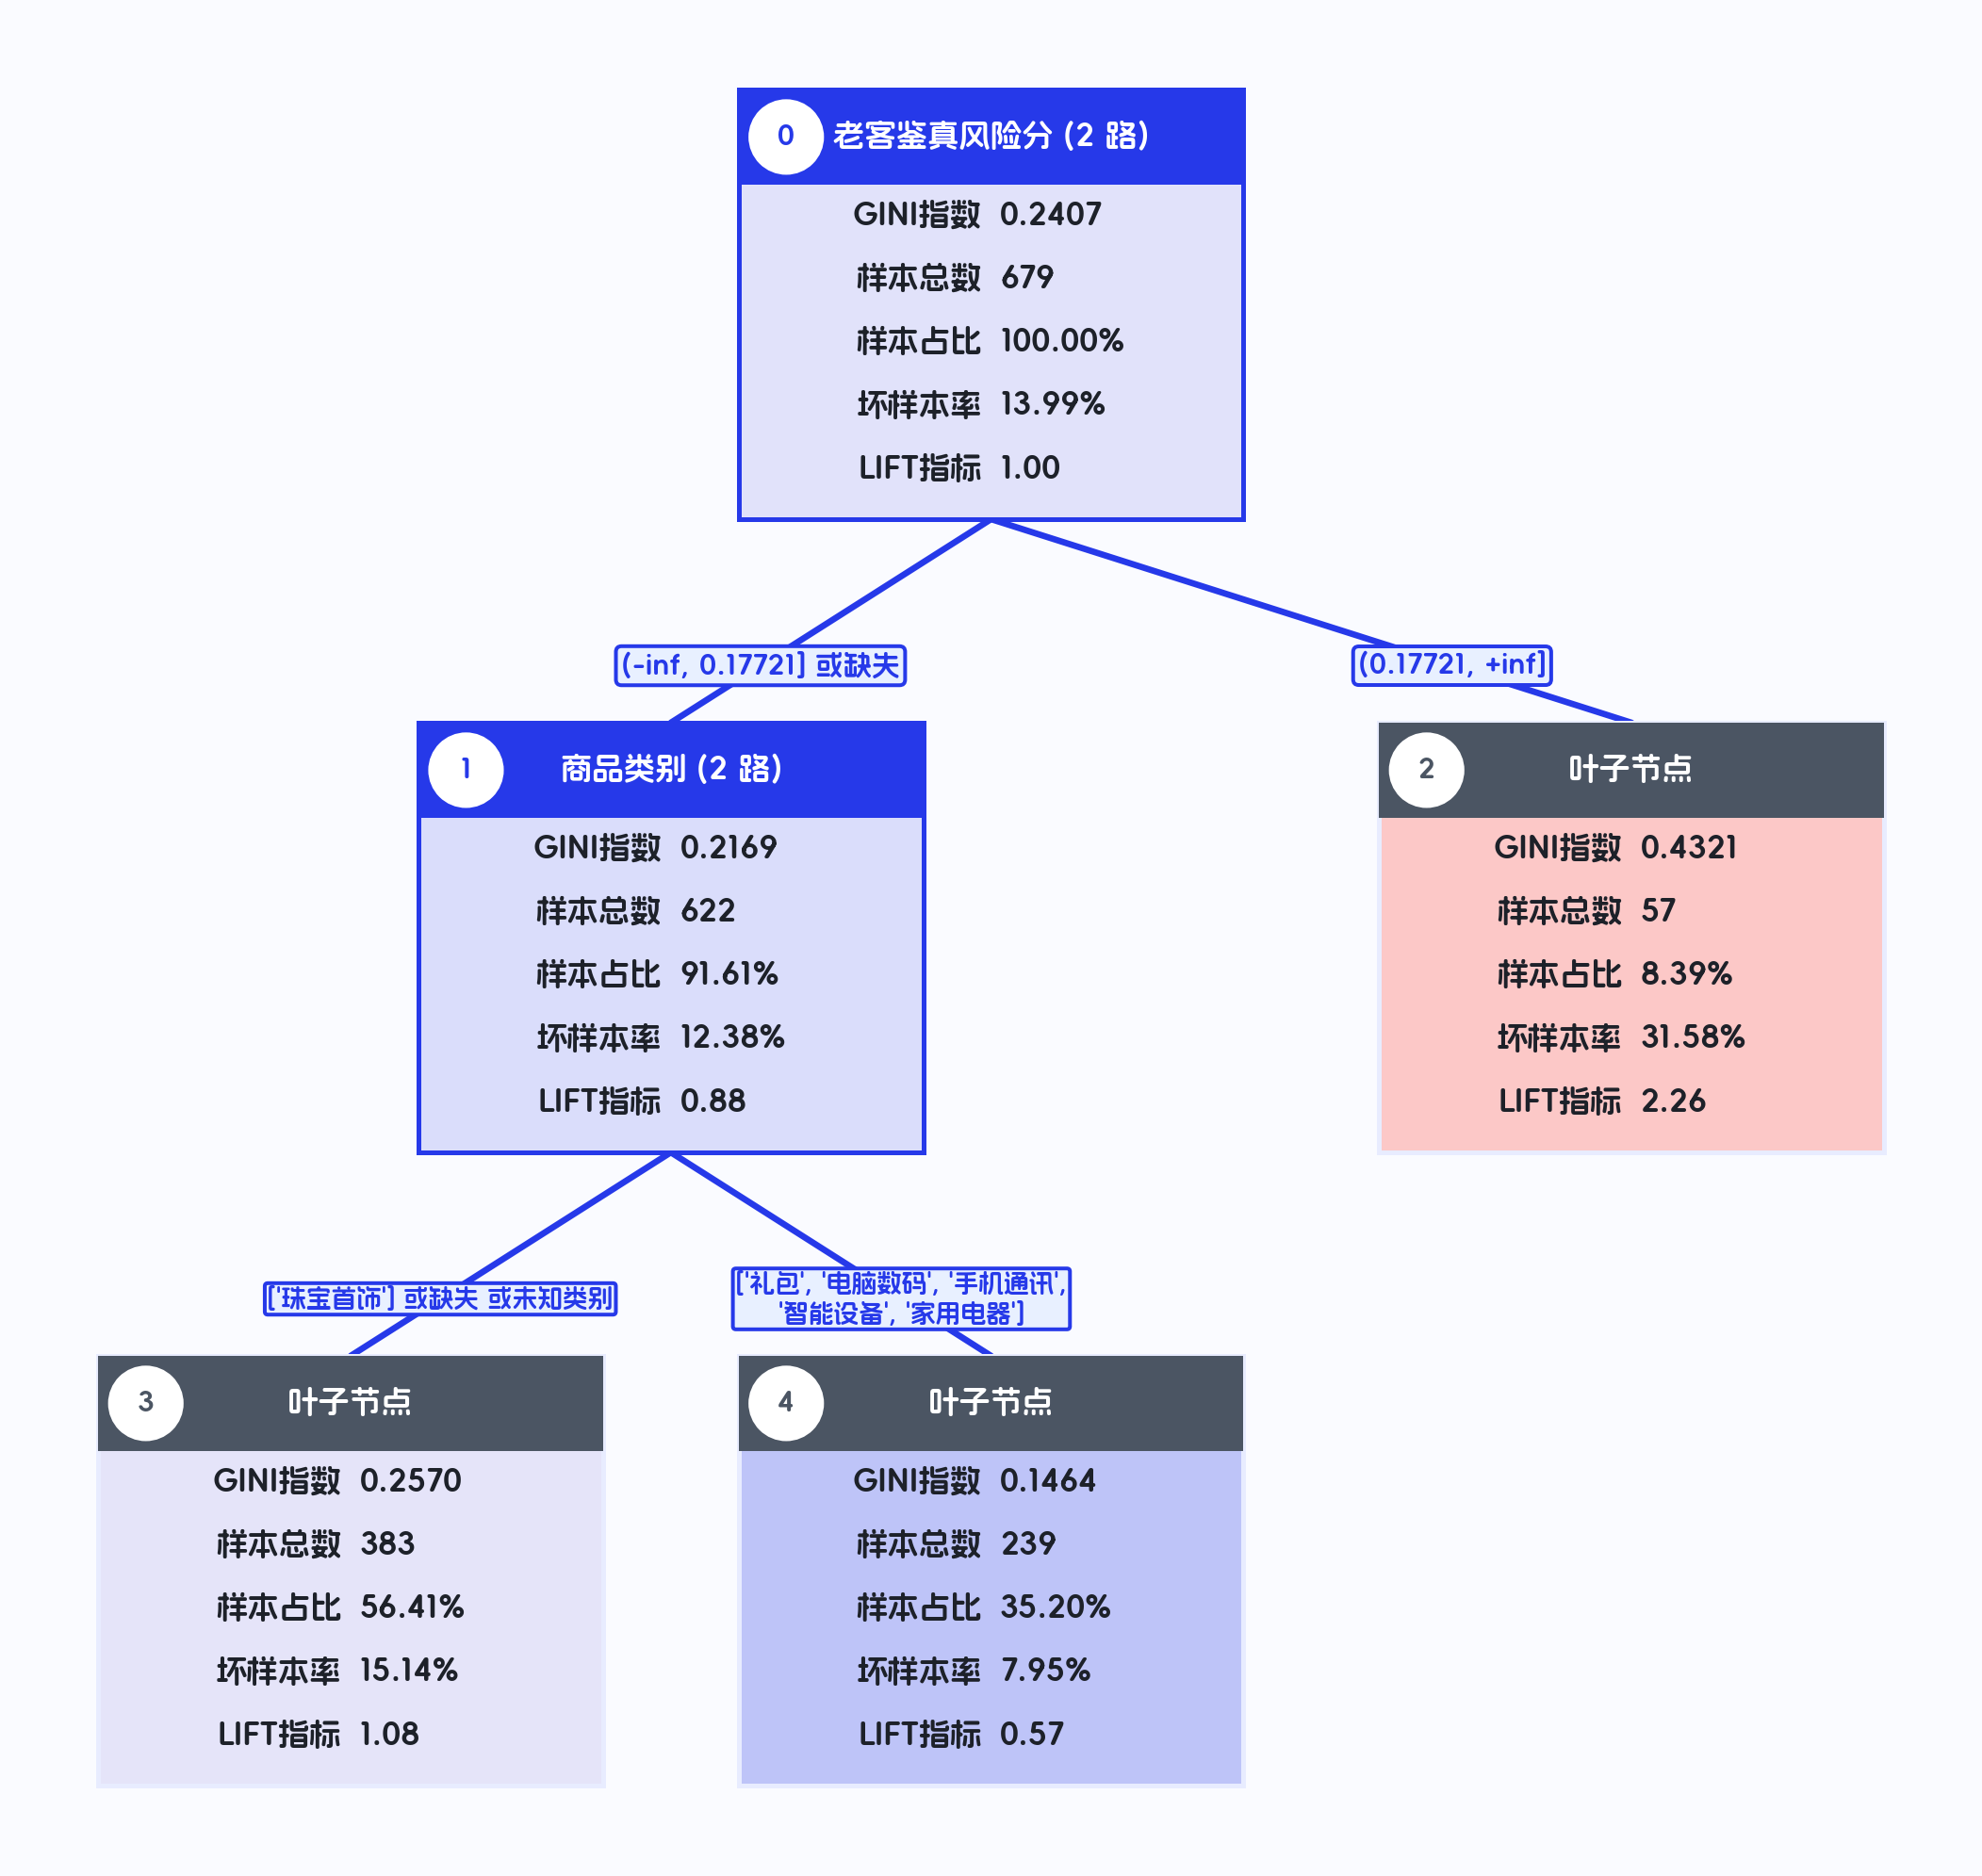

In [2]:
tree = MultiwayTreeExtractor(
    target='FPD', features=features, max_branches=4, max_depth=2,
    min_samples_leaf=20, criterion='chi2', alpha=0.2,
    feature_map={'衡枢鉴真分老客版': '老客鉴真风险分'},
).fit(train)
display(tree.get_split_candidates(node=0))
display(tree.get_node_table())
fig = plot_tree(tree, save=str(output_dir / '自动多叉树.png'))
baseline = tree.evaluate({'训练集': train, '测试集': test})
display(baseline)

## 2. 人工指定三个阈值，直接生成四个分支
区间为左开右闭，缺失值可指定进入某个分支。操作会替换当前节点后代，其他子树不变。

,节点编号,是否叶子,指标含义,样本总数,样本占比,好样本数,好样本占比,坏样本数,坏样本占比,坏样本率,LIFT值,坏账改善,风险拒绝比,准确率,精确率,召回率,F1分数,入参字段,字段含义
0,5,是,"衡枢鉴真分老客版: (-inf, 0.12] 或缺失",493,72.61%,437,74.83%,56,58.95%,11.36%,0.81,-49.86%,-68.68%,29.90%,11.36%,58.95%,19.05%,衡枢鉴真分老客版,老客鉴真风险分
1,6,是,"衡枢鉴真分老客版: (0.12, 0.18]",133,19.59%,111,19.01%,22,23.16%,16.54%,1.18,4.44%,22.67%,72.90%,16.54%,23.16%,19.30%,衡枢鉴真分老客版,老客鉴真风险分
2,7,是,"衡枢鉴真分老客版: (0.18, 0.25]",43,6.33%,31,5.31%,12,12.63%,27.91%,1.99,6.72%,106.19%,83.21%,27.91%,12.63%,17.39%,衡枢鉴真分老客版,老客鉴真风险分
3,8,是,"衡枢鉴真分老客版: (0.25, +inf]",10,1.47%,5,0.86%,5,5.26%,50.00%,3.57,3.85%,261.22%,86.01%,50.00%,5.26%,9.52%,衡枢鉴真分老客版,老客鉴真风险分


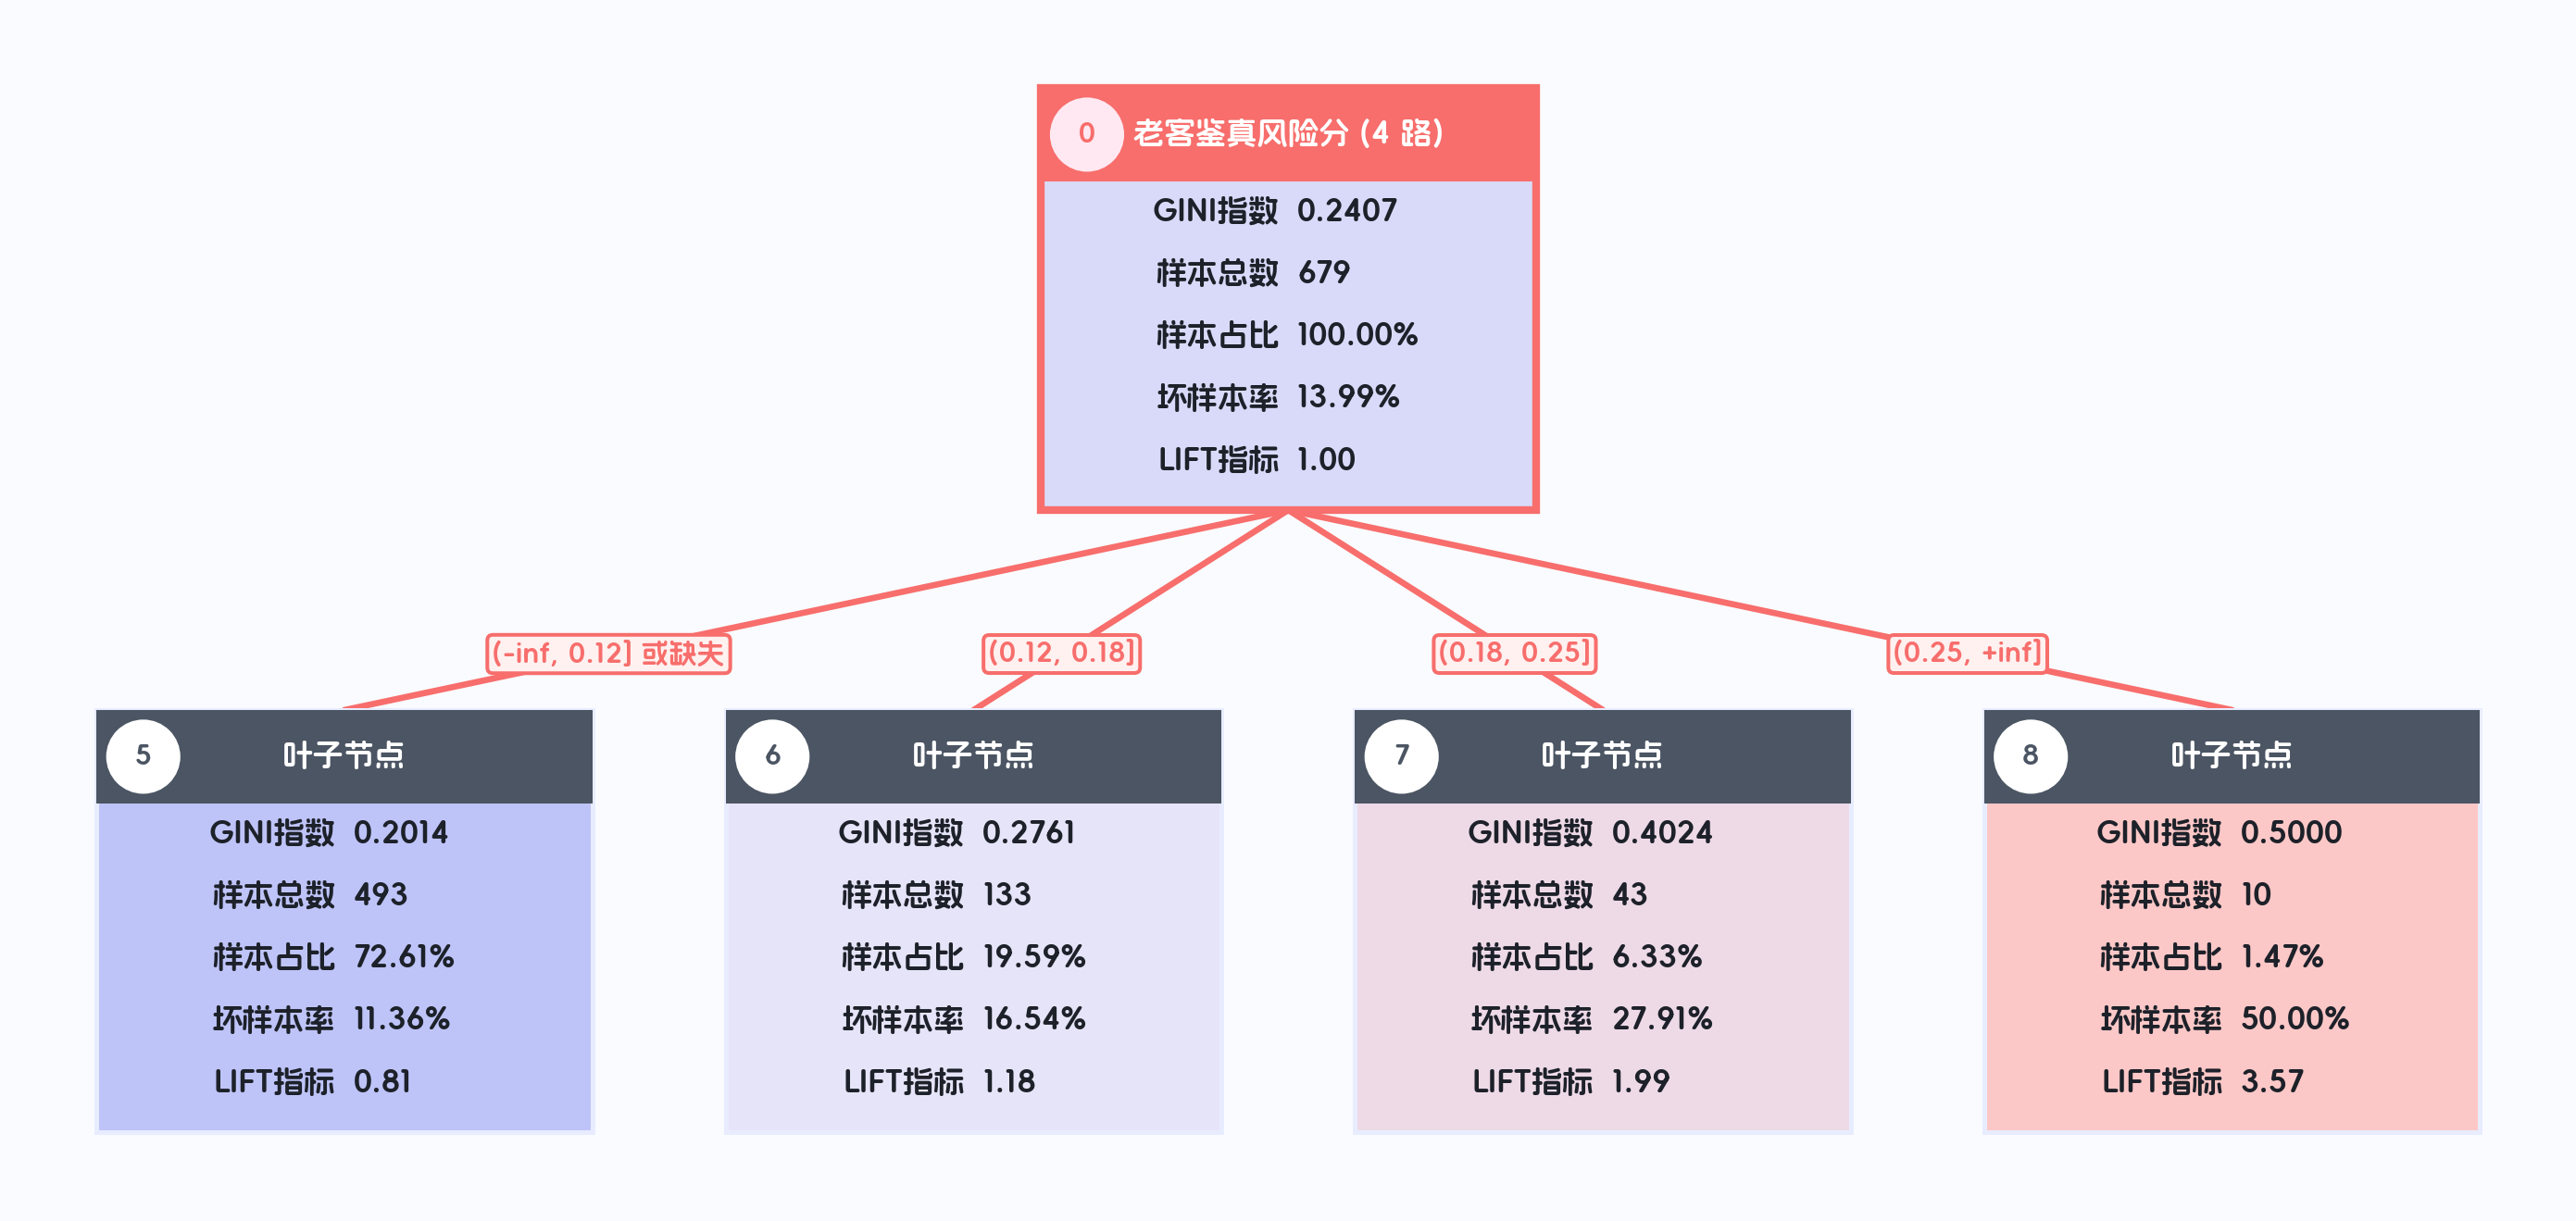

In [3]:
edited = copy.deepcopy(tree)
edited.manual_split(feature=features[0], thresholds=[0.12, 0.18, 0.25], node=0, missing_branch=0)
assert len(edited.nodes_[0].children) == 4
fig = plot_tree(edited, save=str(output_dir / '手工四叉树.png'))
display(style_rule_table(edited.get_rule_table(leaf_only=True)))

## 3. 调整阈值、继续分裂、剪枝
节点编号从 `nodes_` 或节点表中读取，不假定编号连续。人工空分支保留 0 样本，预测继承非空祖先概率。

,节点编号,父节点,深度,是否叶子,分裂特征,切分点,类别分组,子节点,缺失分支,缺失独立分支,样本总数,规则表达式,类别_0样本数,类别_1样本数
0,0,NaN,0,否,衡枢鉴真分老客版,"[0.1, 0.2, 0.3]",[],"[9, 10, 11, 12]",0,否,679,True,584,95
1,9,0.0000,1,否,商品类别,[],"[[珠宝首饰, 电脑数码], [礼包, 手机通讯, 智能设备]]","[13, 14]",0,否,408,(((衡枢鉴真分老客版 <= 0.1) & (衡枢鉴真分老客版.notna())) | (衡枢鉴真分老客版.isna())),361,47
2,10,0.0000,1,是,NaN,[],[],[],0,否,243,((衡枢鉴真分老客版 > 0.1) & (衡枢鉴真分老客版 <= 0.2) & (衡枢鉴真分老客版.notna())),205,38
3,11,0.0000,1,是,NaN,[],[],[],0,否,27,((衡枢鉴真分老客版 > 0.2) & (衡枢鉴真分老客版 <= 0.3) & (衡枢鉴真分老客版.notna())),17,10
4,12,0.0000,1,是,NaN,[],[],[],0,否,1,((衡枢鉴真分老客版 > 0.3) & (衡枢鉴真分老客版.notna())),1,0
5,13,9.0000,2,是,NaN,[],[],[],0,否,253,"(((衡枢鉴真分老客版 <= 0.1) & (衡枢鉴真分老客版.notna())) | (衡枢鉴真分老客版.isna())) & ((((商品类别 in ['珠宝首饰', '电脑数码']) & (商品类别.notna())) | ((商品类别 not in ['珠宝首饰', '电脑数码', '礼包', '手机通讯', '智能设备']) & (商品类别.notna()))) | (商品类别.isna()))",217,36
6,14,9.0000,2,是,NaN,[],[],[],0,否,155,"(((衡枢鉴真分老客版 <= 0.1) & (衡枢鉴真分老客版.notna())) | (衡枢鉴真分老客版.isna())) & ((商品类别 in ['礼包', '手机通讯', '智能设备']) & (商品类别.notna()))",144,11


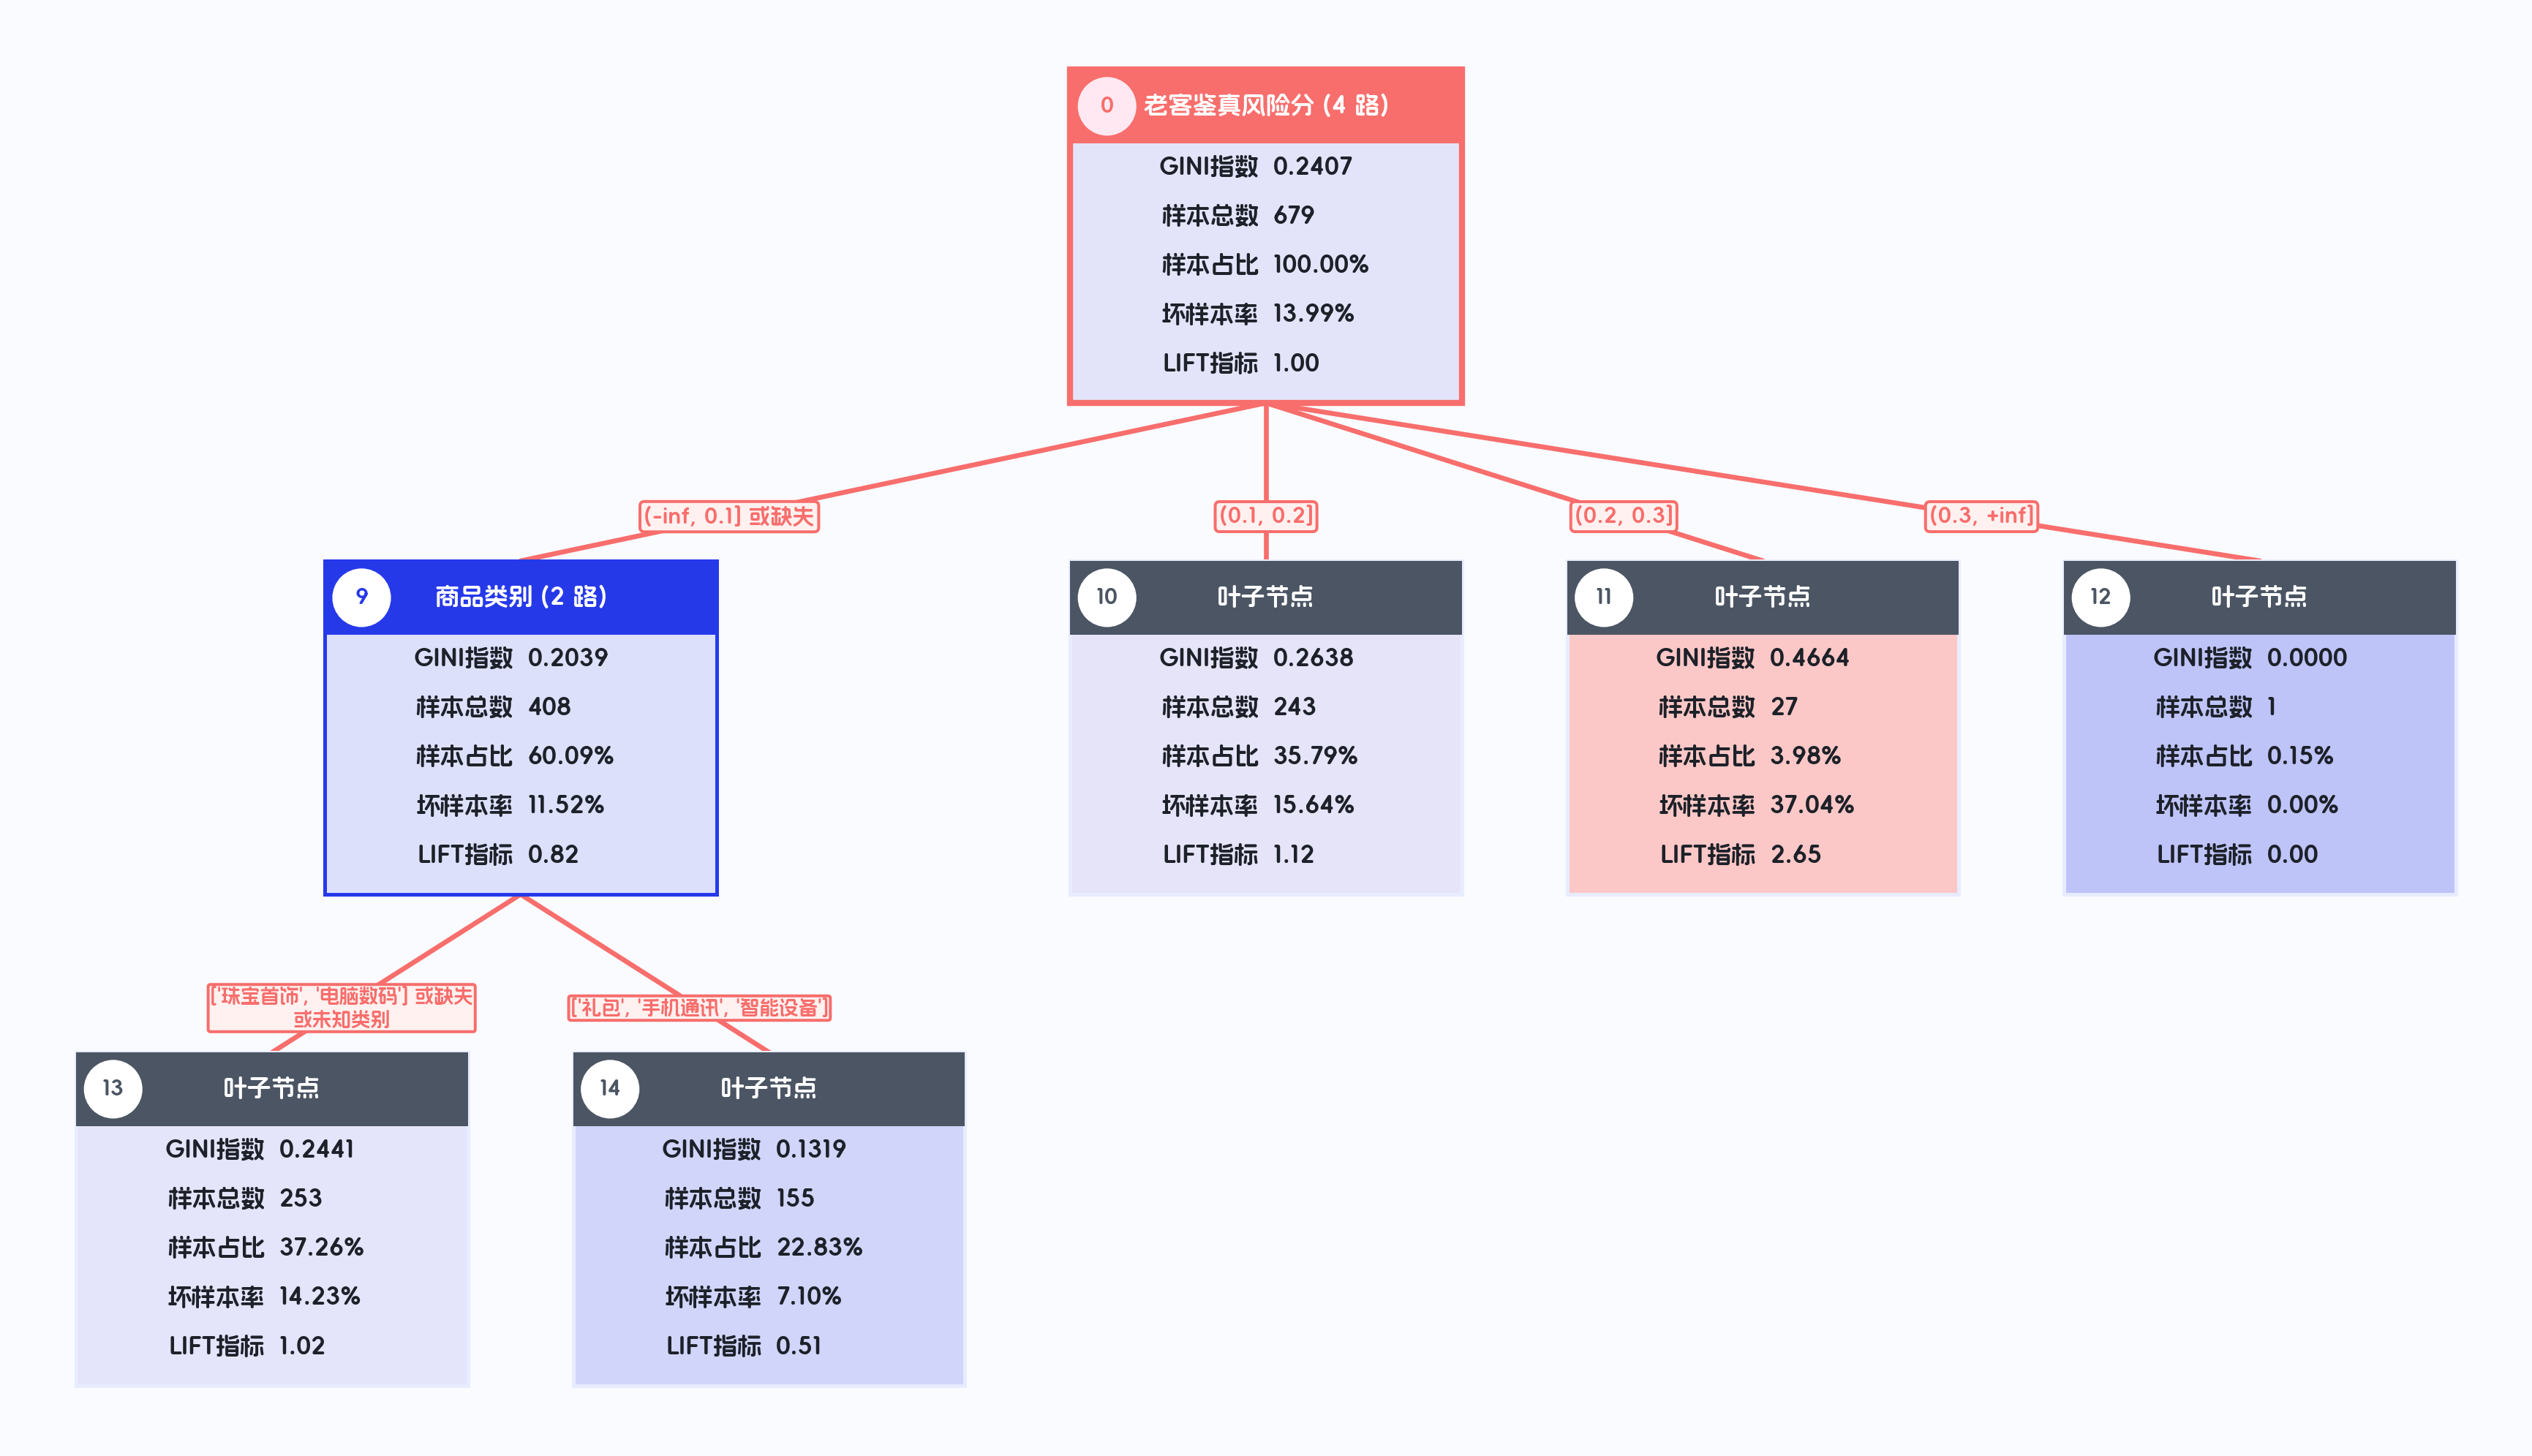

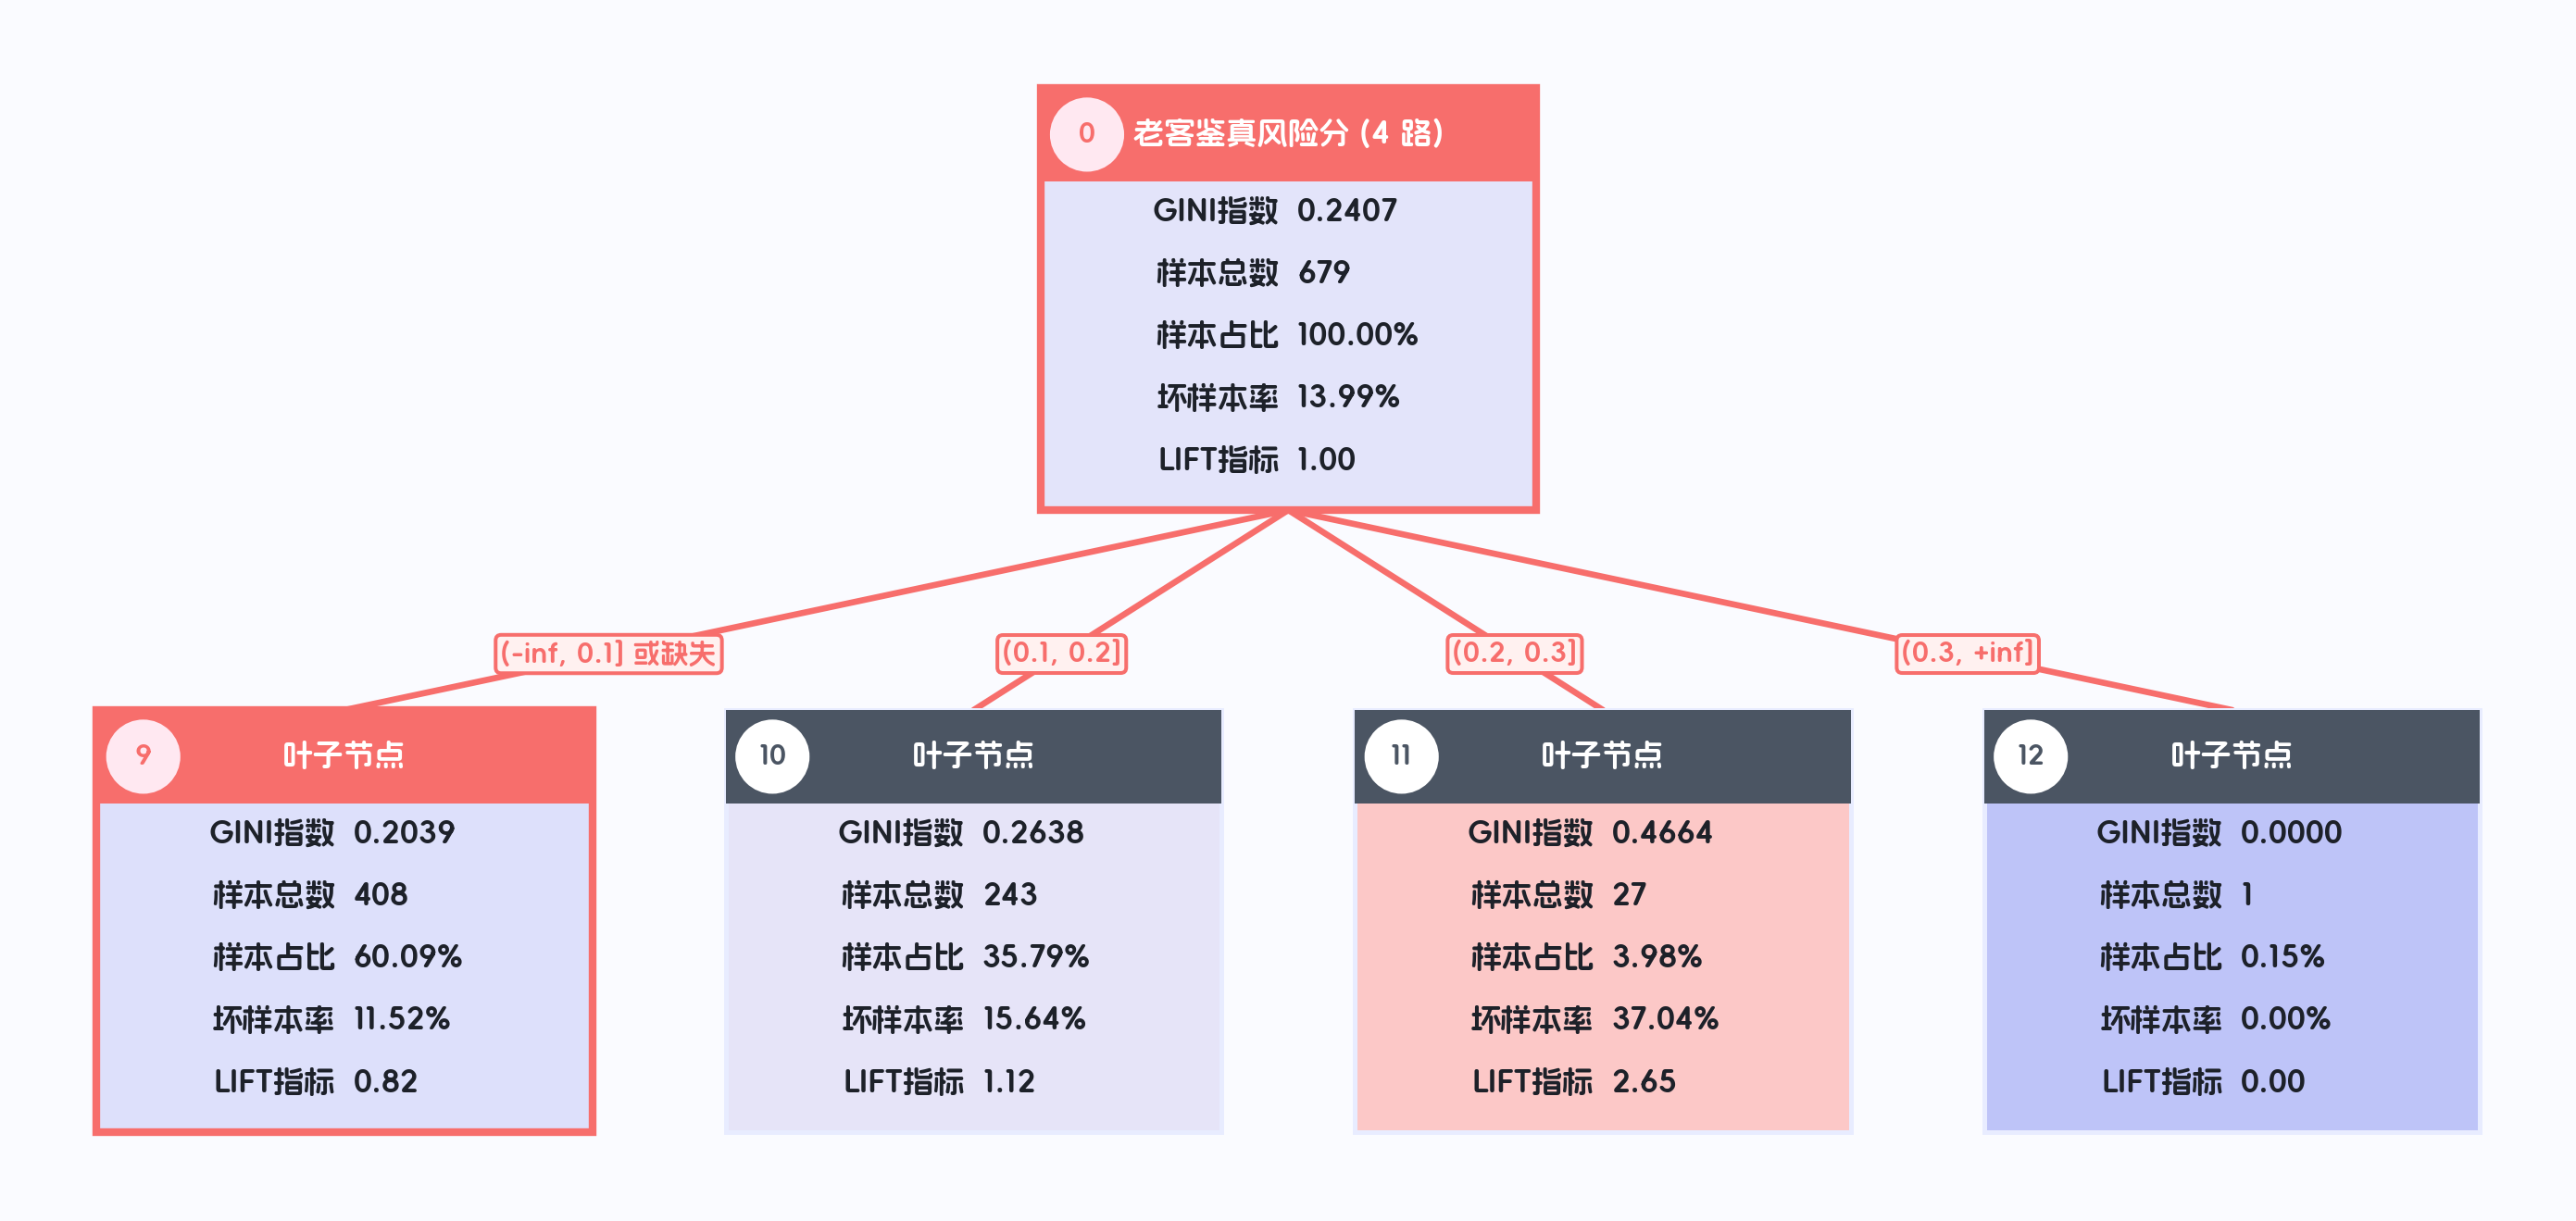

In [4]:
edited.set_thresholds(0, [0.10, 0.20, 0.30], missing_branch=0)
child = max(edited.nodes_[0].children, key=lambda node: edited.nodes_[node].counts.sum())
edited.grow(node=child)
fig = plot_tree(edited, save=str(output_dir / '继续生长.png'))
display(edited.get_node_table())
edited.prune(node=child)
assert not edited.nodes_[child].children
fig = plot_tree(edited, save=str(output_dir / '节点剪枝.png'))

## 4. 类别分组也可以人工调整
未知类别跟随保存的缺失分支；下面用商品类别演示完整分组。

,节点编号,父节点,深度,是否叶子,分裂特征,切分点,类别分组,子节点,缺失分支,缺失独立分支,样本总数,规则表达式,类别_0样本数,类别_1样本数
0,0,NaN,0,否,商品类别,[],"[[珠宝首饰], [礼包], [手机通讯], [电脑数码, 智能设备, 家用电器]]","[5, 6, 7, 8]",0,否,679,True,584,95
1,5,0.0000,1,是,NaN,[],[],[],0,否,421,"((((商品类别 in ['珠宝首饰']) & (商品类别.notna())) | ((商品类别 not in ['珠宝首饰', '礼包', '手机通讯', '电脑数码', '智能设备', '家用电器']) & (商品类别.notna()))) | (商品类别.isna()))",354,67
2,6,0.0000,1,是,NaN,[],[],[],0,否,141,((商品类别 in ['礼包']) & (商品类别.notna())),125,16
3,7,0.0000,1,是,NaN,[],[],[],0,否,98,((商品类别 in ['手机通讯']) & (商品类别.notna())),88,10
4,8,0.0000,1,是,NaN,[],[],[],0,否,19,"((商品类别 in ['电脑数码', '智能设备', '家用电器']) & (商品类别.notna()))",17,2


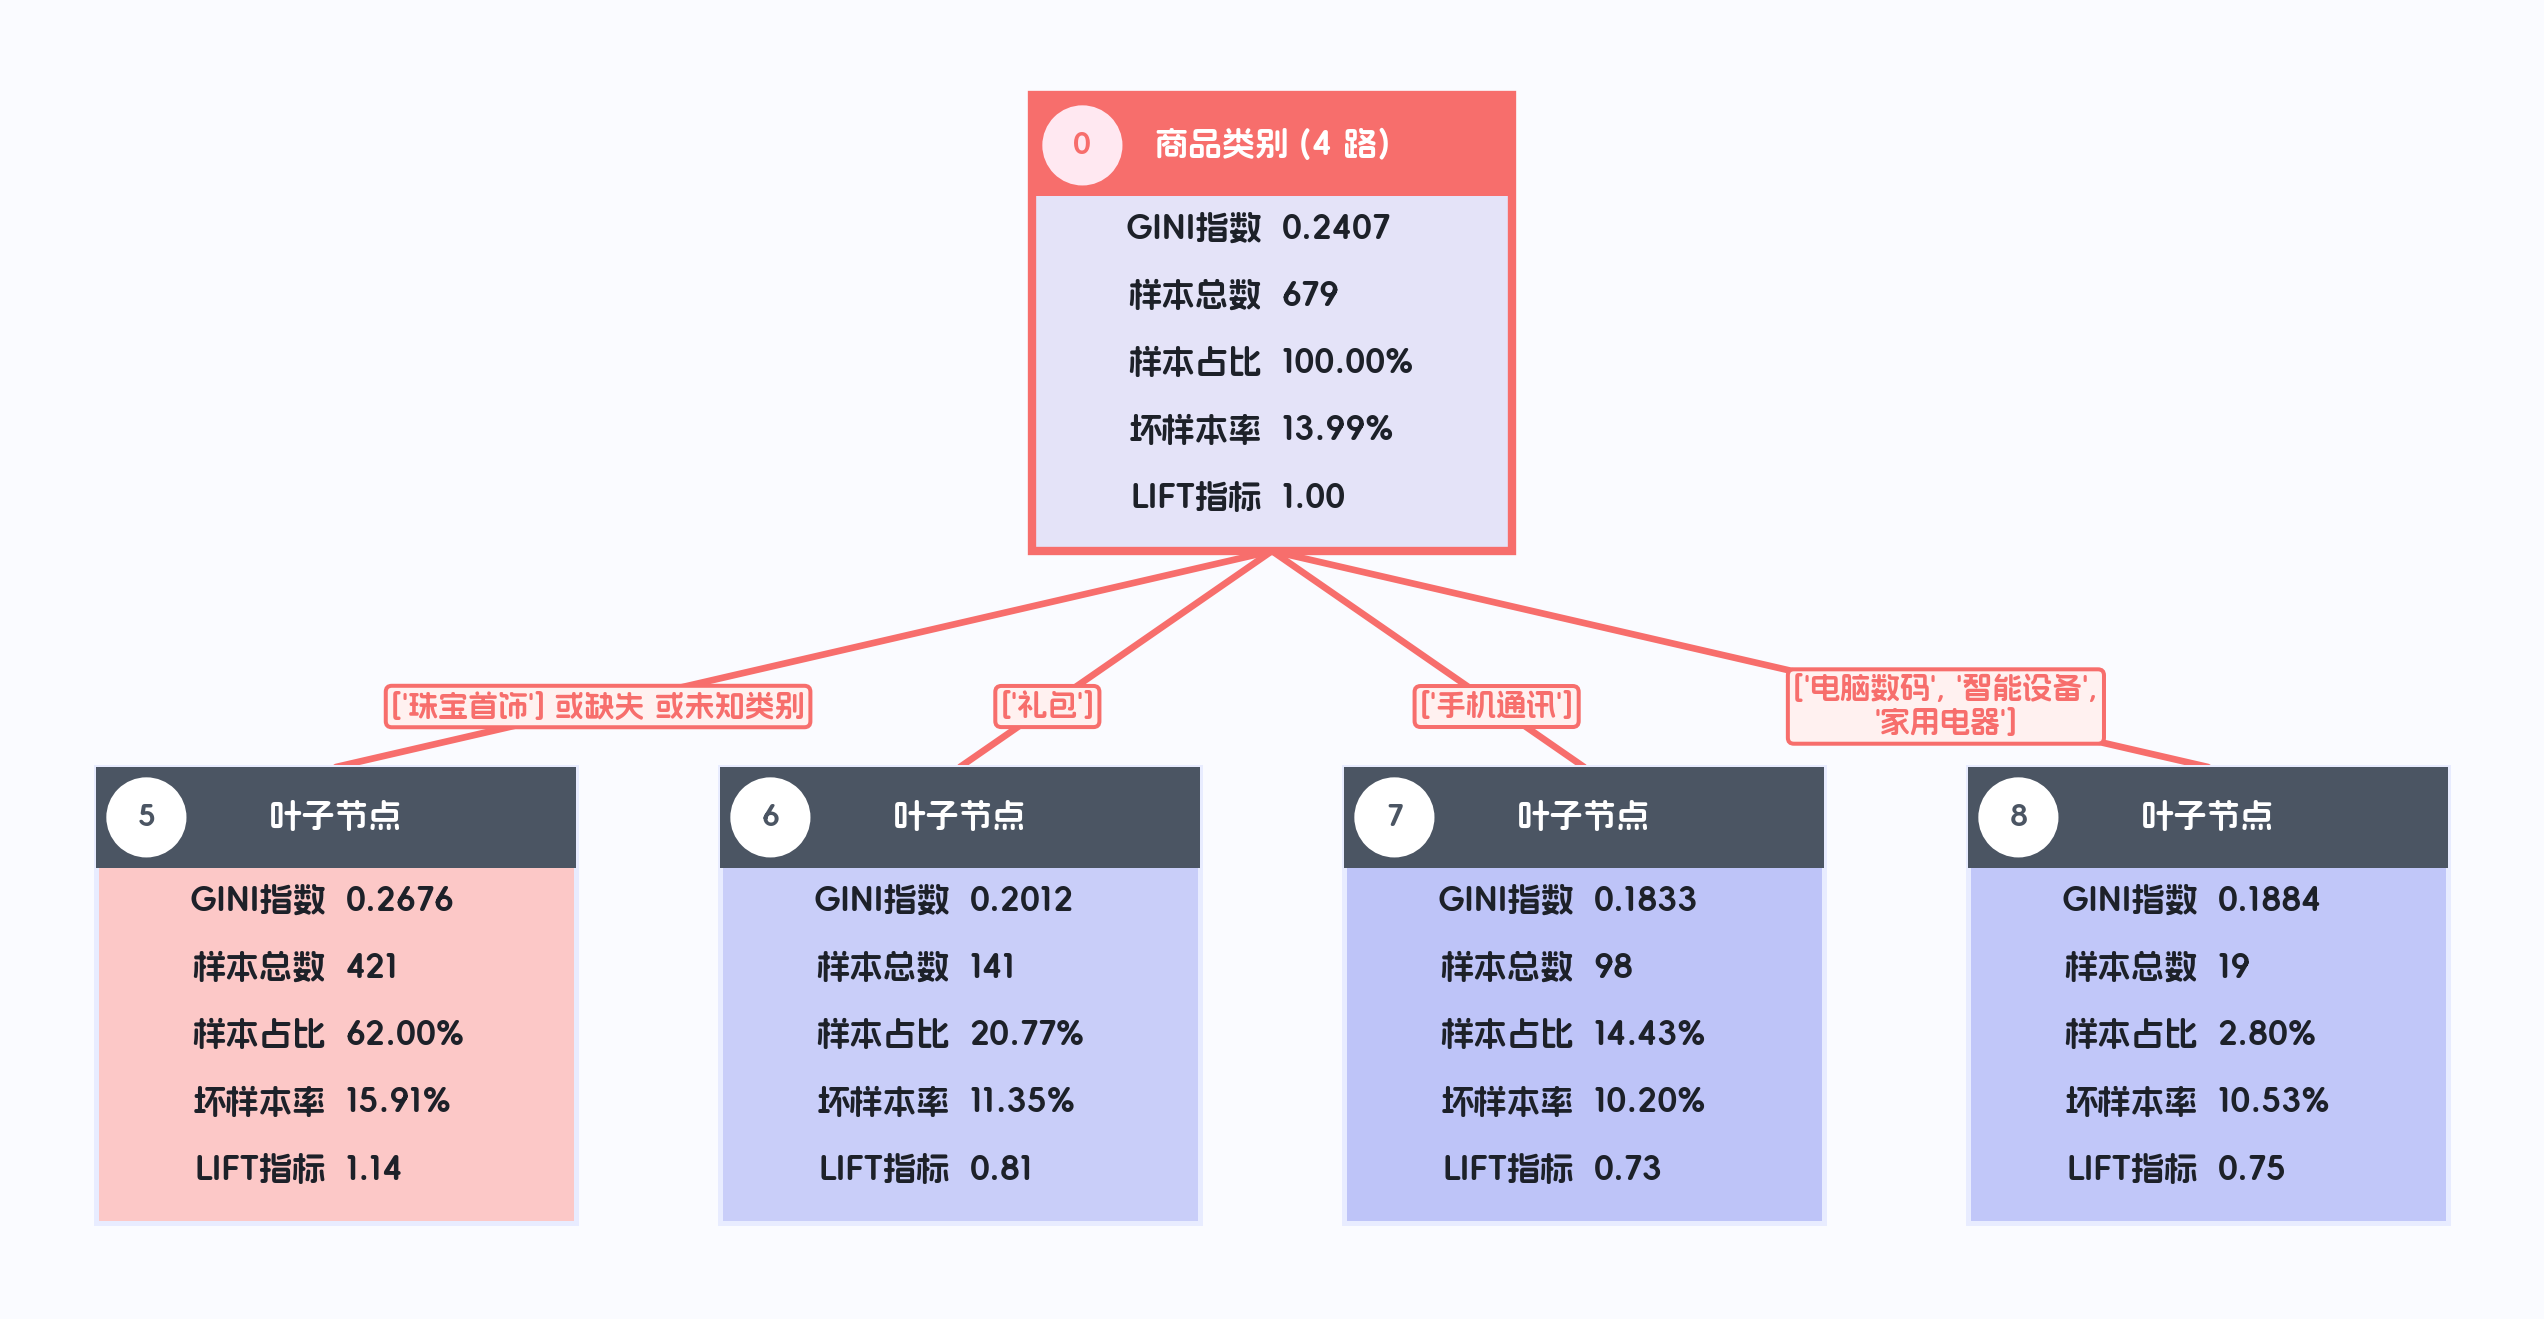

In [5]:
category_tree = copy.deepcopy(tree)
categories = data['商品类别'].dropna().unique().tolist()
train_categories = train['商品类别'].dropna().unique().tolist()
if len(train_categories) >= 2:
    groups = [[value] for value in train_categories[:3]]
    if len(train_categories) > 3:
        groups.append(train_categories[3:])
    category_tree.manual_split(feature='商品类别', category_groups=groups, node=0, missing_branch=0)
    display(category_tree.get_node_table())
    fig = plot_tree(category_tree, save=str(output_dir / '类别多叉树.png'))

## 5. 规则集与模型效果
全叶规则互斥且覆盖全部样本。业务拒绝策略应明确挑选风险叶节点，而不是将所有叶子做 OR。

In [6]:
leaf_table = edited.report(test, leaf_only=True)
display(style_rule_table(leaf_table))
display(pd.concat([baseline.assign(模型='自动多叉树'), edited.evaluate({'训练集': train, '测试集': test}).assign(模型='人工调整树')], ignore_index=True))

rules = edited.get_rules()
masks = np.column_stack([rule.predict(test).to_numpy() for rule in rules])
assert np.all(masks.sum(axis=1) == 1)
assert leaf_table['样本总数'].sum() == len(test)
for rule in rules:
    print(rule.name, rule.expr)

risk_node = int(leaf_table.sort_values('坏样本率', ascending=False).iloc[0]['节点编号'])
strategy = edited.to_ruleset(nodes=[risk_node])
matched, details = strategy.evaluate(test)
print(f'选定风险叶节点 {risk_node}，命中 {matched.sum()} 人')
display(edited.report(test, overdue=['MOB1'], dpds=[7, 3, 0], amount='放款金额', leaf_only=True))

,节点编号,是否叶子,指标含义,样本总数,样本占比,好样本数,好样本占比,坏样本数,坏样本占比,坏样本率,LIFT值,坏账改善,风险拒绝比,准确率,精确率,召回率,F1分数,入参字段,字段含义
0,9,是,"衡枢鉴真分老客版: (-inf, 0.1] 或缺失",185,63.57%,166,66.40%,19,46.34%,10.27%,0.73,-47.31%,-74.41%,35.40%,10.27%,46.34%,16.81%,衡枢鉴真分老客版,老客鉴真风险分
1,10,是,"衡枢鉴真分老客版: (0.1, 0.2]",90,30.93%,74,29.60%,16,39.02%,17.78%,1.26,11.72%,37.90%,65.98%,17.78%,39.02%,24.43%,衡枢鉴真分老客版,老客鉴真风险分
2,11,是,"衡枢鉴真分老客版: (0.2, 0.3]",16,5.50%,10,4.00%,6,14.63%,37.50%,2.66,9.67%,175.83%,84.54%,37.50%,14.63%,21.05%,衡枢鉴真分老客版,老客鉴真风险分
3,12,是,"衡枢鉴真分老客版: (0.3, +inf]",0,0.00%,0,0.00%,0,0.00%,0.00%,0.00,0.00%,0.00%,85.91%,0.00%,0.00%,0.00%,衡枢鉴真分老客版,老客鉴真风险分


,数据集,样本总数,准确率,交叉熵,AUC,KS,模型
0,训练集,679,0.8601,0.3899,0.6207,0.1767,自动多叉树
1,测试集,291,0.8591,0.4004,0.5682,0.1187,自动多叉树
2,训练集,679,0.8601,0.3961,0.5756,0.1251,人工调整树
3,测试集,291,0.8591,0.3926,0.6141,0.2006,人工调整树


MultiwayTree_N9 (((衡枢鉴真分老客版 <= 0.1) & (衡枢鉴真分老客版.notna())) | (衡枢鉴真分老客版.isna()))
MultiwayTree_N10 ((衡枢鉴真分老客版 > 0.1) & (衡枢鉴真分老客版 <= 0.2) & (衡枢鉴真分老客版.notna()))
MultiwayTree_N11 ((衡枢鉴真分老客版 > 0.2) & (衡枢鉴真分老客版 <= 0.3) & (衡枢鉴真分老客版.notna()))
MultiwayTree_N12 ((衡枢鉴真分老客版 > 0.3) & (衡枢鉴真分老客版.notna()))
选定风险叶节点 11，命中 16 人


分箱详情                                                                                                                                  MOB1 7+         ... MOB1 0+                                                         分箱详情         
  节点编号 是否叶子  规则分类                                                            指标名称  分箱        样本总数   样本占比                       指标含义        好样本数  好样本占比  ...    坏样本率  LIFT值    坏账改善   风险拒绝比    准确率    精确率    召回率   F1分数      入参字段     字段含义
0    9    是  验证规则  (((衡枢鉴真分老客版 <= 0.1) & (衡枢鉴真分老客版.notna())) | (衡枢鉴真分老客版.isna()))  命中 798337.0000 0.6426  衡枢鉴真分老客版: (-inf, 0.1] 或缺失 689810.0000 0.6671  ...  0.1968 0.9310 -0.1240 -0.1930 0.3883 0.1784 0.5593 0.2705  衡枢鉴真分老客版  老客鉴真风险分
1   10    是  验证规则     ((衡枢鉴真分老客版 > 0.1) & (衡枢鉴真分老客版 <= 0.2) & (衡枢鉴真分老客版.notna()))  命中 368808.0000 0.2969       衡枢鉴真分老客版: (0.1, 0.2] 297554.0000 0.2878  ...  0.2087 0.9877 -0.0052 -0.0175 0.6254 0.2222 0.3390 0.2685  衡枢鉴真分老客版  老客鉴真风险分
2   11    是  验证规则     ((衡枢鉴真分老客版 > 0.2) & (衡枢鉴真分老客版 <= 0.3) & (衡枢鉴真分老客版.notna()))  命中  75194.0000 0.0605       衡枢鉴真分老客版: (0.2, 0.3]  46703.0000 0.0452  ...  0.3789 1.7928  0.0511  0.8439 0.7835 0.3750 0.1017 0.1600  衡枢鉴真分老客版  老客鉴真风险分
3   12    是  验证规则                         ((衡枢鉴真分老客版 > 0.3) & (衡枢鉴真分老客版.notna()))  命中      0.0000 0.0000      衡枢鉴真分老客版: (0.3, +inf]      0.0000 0.0000  ...  0.0000 0.0000  0.0000  0.0000 0.7973 0.0000 0.0000 0.0000  衡枢鉴真分老客版  老客鉴真风险分

[4 rows x 46 columns]

## 6. 保存模型与三种绘图后端
模型包含类别顺序、人工阈值和缺失/未知类别归属。只加载可信来源的模型文件。

In [7]:
model_path = output_dir / '多叉树.pkl'
edited.save(model_path)
restored = MultiwayTreeExtractor.load(model_path)
np.testing.assert_allclose(restored.predict_proba(test), edited.predict_proba(test))
chart = plot_tree(restored, backend='pyecharts', save=str(output_dir / '多叉树.html'))
dot = plot_tree(restored, backend='graphviz')
(output_dir / '多叉树.gv').write_text(dot.source, encoding='utf-8')
print(f'模型与图形已保存到 {output_dir}')

模型与图形已保存到 E:\workspace\hscredit\examples\model_report\multiway_tree


## 7. 多分类节点分布
多分类节点逐类显示样本数和占比，模型评估提供准确率、交叉熵和 OVR AUC。

,数据集,样本总数,准确率,交叉熵,AUC
0,训练集,120,1.0000,0.0000,1.0000


分箱详情                                                                                                                                                              类别_已结清         ... 类别_逾期                                                                 
  节点编号 是否叶子  规则分类                                                                                                       指标名称  分箱 样本总数   样本占比                   指标含义   好样本数  好样本占比  ...  坏样本数  坏样本占比   坏样本率  LIFT值    坏账改善   风险拒绝比    准确率    精确率    召回率   F1分数
0    1    是  验证规则  ((((账龄分组 in ['短']) & (账龄分组.notna())) | ((账龄分组 not in ['短', '中', '长']) & (账龄分组.notna()))) | (账龄分组.isna()))  命中   40 0.3333  账龄分组: ['短'] 或缺失 或未知类别     40 0.5000  ...     0 0.0000 0.0000 0.0000 -0.5000 -1.5000 0.3333 0.0000 0.0000 0.0000
1    2    是  验证规则                                                                         ((账龄分组 in ['中']) & (账龄分组.notna()))  命中   40 0.3333            账龄分组: ['中']      0 0.0000  ...     0 0.0000 0.0000 0.0000 -0.5000 -1.5000 0.3333 0.0000 0.0000 0.0000
2    3    是  验证规则                                                                         ((账龄分组 in ['长']) & (账龄分组.notna()))  命中   40 0.3333            账龄分组: ['长']     40 0.5000  ...    40 1.0000 1.0000 3.0000  1.0000  3.0000 1.0000 1.0000 1.0000 1.0000

[3 rows x 44 columns]

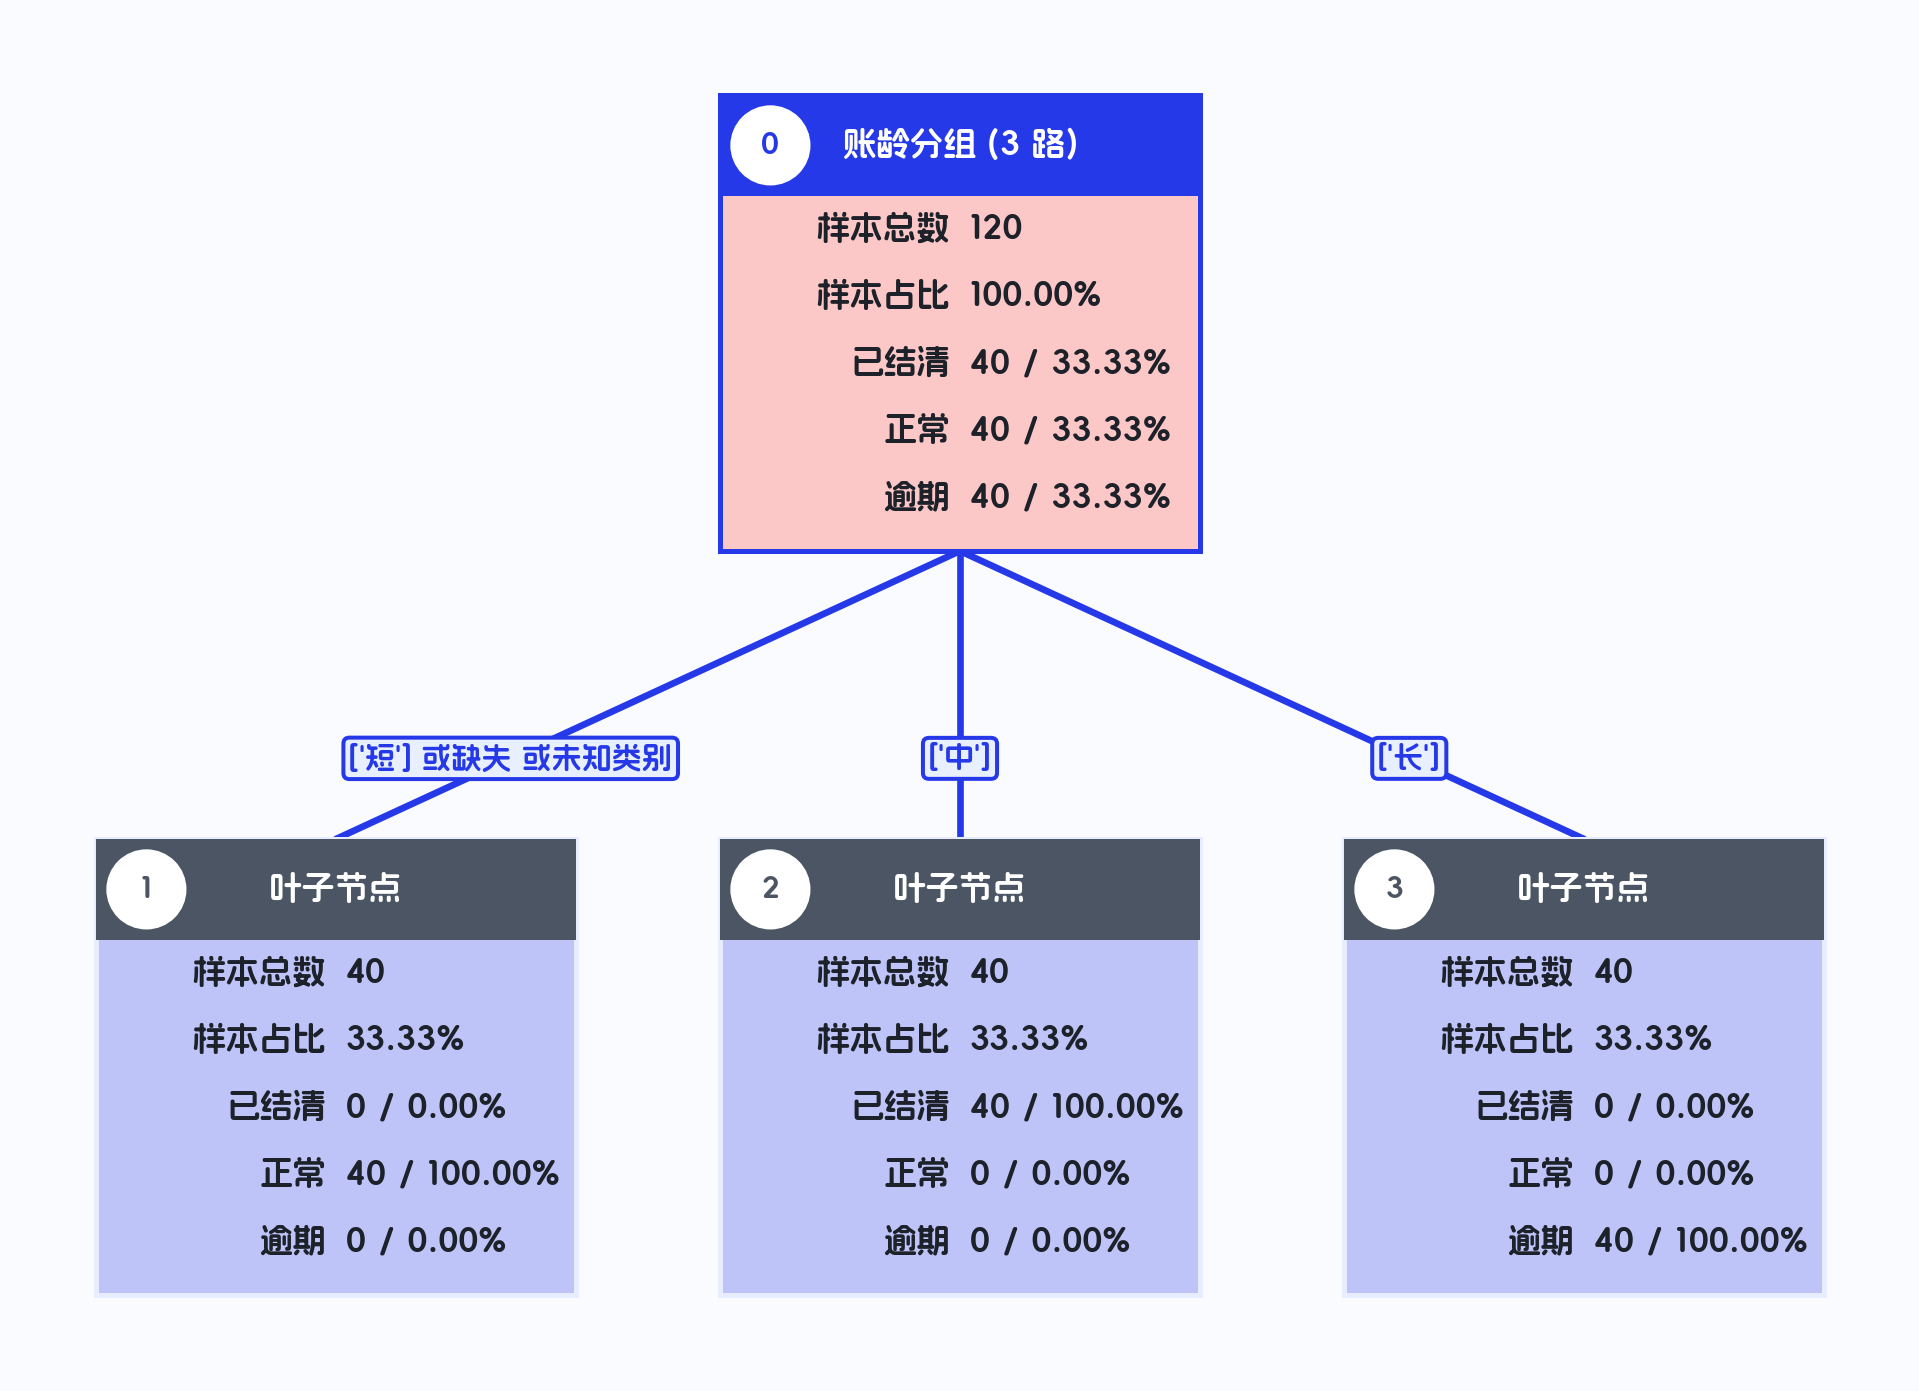

In [8]:
status_data = pd.DataFrame({
    '账龄分组': ['短', '中', '长'] * 40,
    '账户状态': ['正常', '已结清', '逾期'] * 40,
})
status_tree = MultiwayTreeExtractor(target='账户状态', max_branches=4, max_depth=2).fit(status_data)
assert len(status_tree.nodes_[0].children) == 3
fig = plot_tree(status_tree, save=str(output_dir / '多分类三叉树.png'))
display(status_tree.evaluate())
display(status_tree.get_rule_table(leaf_only=True))

## 8. 缺失值独立成一个分支

与 binner 一致，独立分支用 `missing_separate=True` 声明。
三个有限阈值对应四个普通分支，再加缺失分支共五叉，所以设置 `max_branches=5`。
下面只在训练数据副本里注入缺失，原始数据和工作簿保持不变。

,节点编号,是否叶子,指标含义,样本总数,样本占比,好样本数,好样本占比,坏样本数,坏样本占比,坏样本率,LIFT值,坏账改善,风险拒绝比,准确率,精确率,召回率,F1分数
0,3,是,"衡枢鉴真分老客版: (0.17816884, +inf]",56,8.25%,38,6.51%,18,18.95%,32.14%,2.30,11.66%,141.40%,83.06%,32.14%,18.95%,23.84%
1,4,是,衡枢鉴真分老客版: 缺失,8,1.18%,6,1.03%,2,2.11%,25.00%,1.79,0.94%,79.62%,85.42%,25.00%,2.11%,3.88%
2,5,是,"衡枢鉴真分老客版: (-inf, 0.14738089] 且 青云24: (-inf, 550]",95,13.99%,77,13.18%,18,18.95%,18.95%,1.35,5.76%,41.19%,77.32%,18.95%,18.95%,18.95%
3,6,是,"衡枢鉴真分老客版: (-inf, 0.14738089] 且 青云24: (550, 581]",92,13.55%,85,14.55%,7,7.37%,7.61%,0.54,-7.15%,-52.77%,74.52%,7.61%,7.37%,7.49%
4,7,是,"衡枢鉴真分老客版: (-inf, 0.14738089] 且 青云24: (581, 596]",49,7.22%,36,6.16%,13,13.68%,26.53%,1.90,6.97%,96.59%,82.62%,26.53%,13.68%,18.06%
5,8,是,"衡枢鉴真分老客版: (-inf, 0.14738089] 且 青云24: (596, +inf]",323,47.57%,297,50.86%,26,27.37%,8.05%,0.58,-38.53%,-81.00%,46.10%,8.05%,27.37%,12.44%
6,9,是,"衡枢鉴真分老客版: (-inf, 0.14738089] 且 青云24: 缺失",0,0.00%,0,0.00%,0,0.00%,0.00%,0.00,0.00%,0.00%,86.01%,0.00%,0.00%,0.00%
7,10,是,"衡枢鉴真分老客版: (0.14738089, 0.17816884] 且 占信V3: (-inf, 400]",1,0.15%,1,0.17%,0,0.00%,0.00%,0.00,-0.15%,-100.15%,85.86%,0.00%,0.00%,0.00%
8,11,是,"衡枢鉴真分老客版: (0.14738089, 0.17816884] 且 占信V3: (400, 600]",42,6.19%,33,5.65%,9,9.47%,21.43%,1.53,3.50%,56.66%,82.47%,21.43%,9.47%,13.14%
9,12,是,"衡枢鉴真分老客版: (0.14738089, 0.17816884] 且 占信V3: (600, +inf]",13,1.91%,11,1.88%,2,2.11%,15.38%,1.10,0.19%,10.15%,84.68%,15.38%,2.11%,3.70%


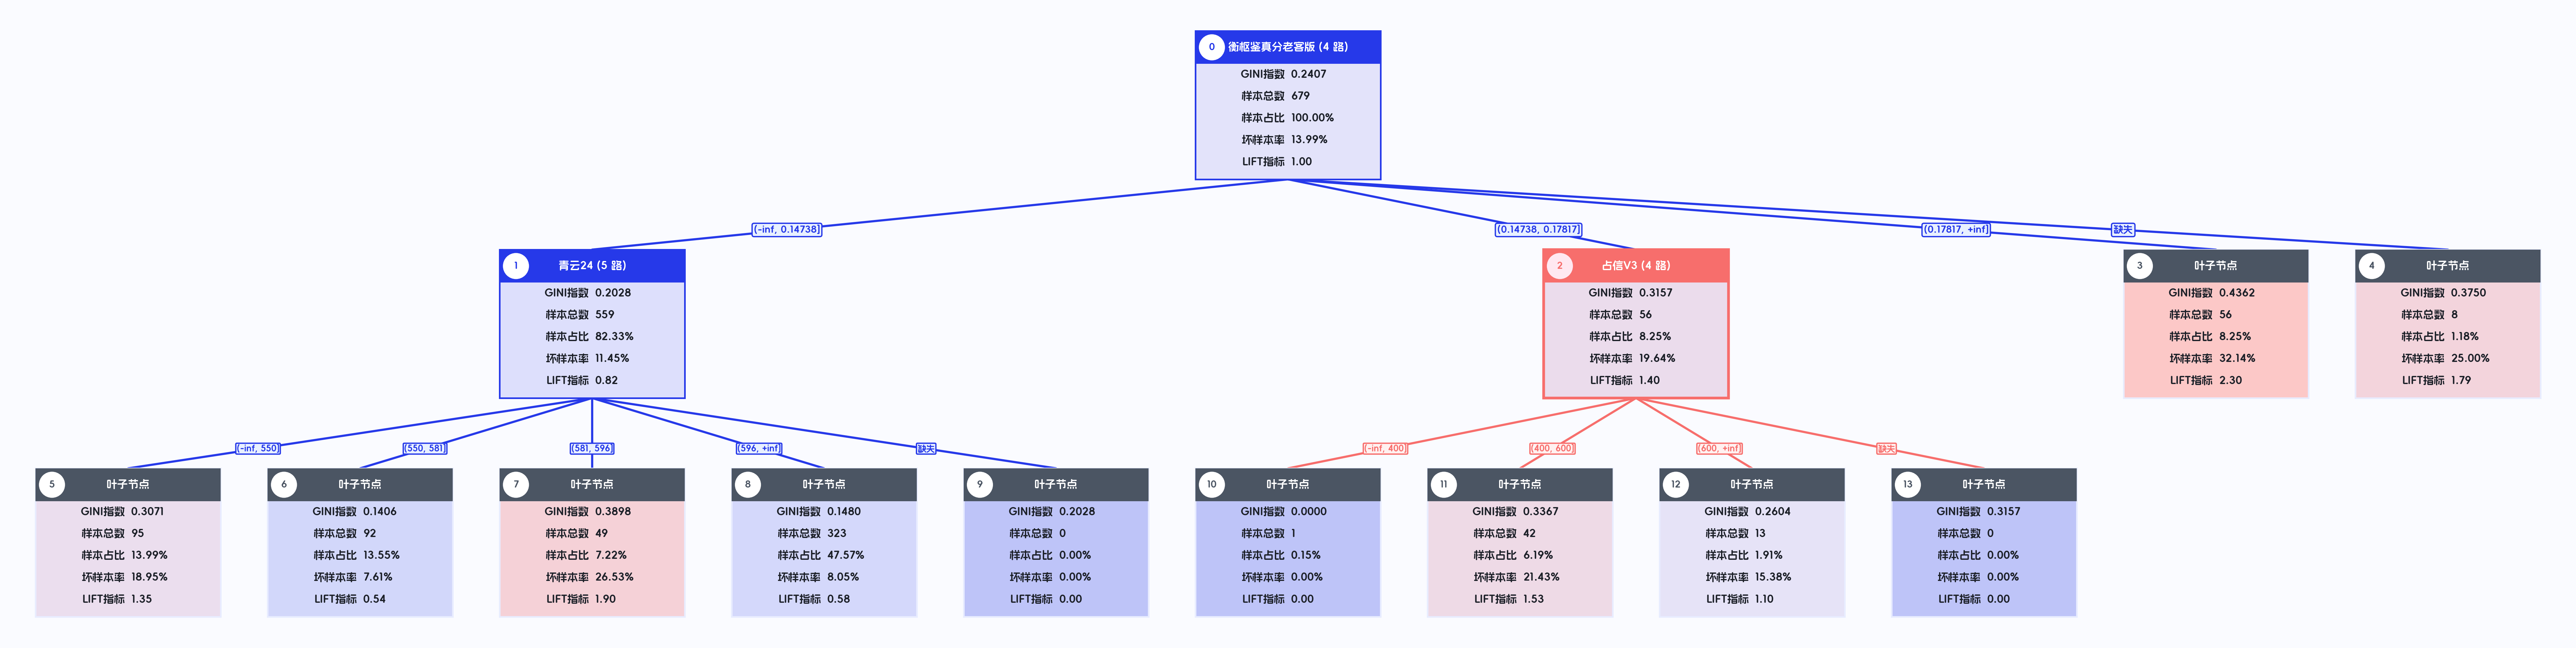

In [9]:
missing_training = train.copy()
missing_training.loc[missing_training.index[:8], features[0]] = np.nan
missing_tree = MultiwayTreeExtractor(
    target='FPD', features=features + ['占信V3'], max_depth=2, max_branches=5,
    missing_separate=True, n_jobs=1,
).fit(missing_training)
missing_tree.manual_split(feature="占信V3", thresholds=[400, 600], node=2, missing_separate=True)
fig = plot_tree(missing_tree, save=str(output_dir / '独立缺失五叉树.png'))
style_rule_table(missing_tree.get_rule_table(leaf_only=True))

,节点编号,是否叶子,指标含义,样本总数,样本占比,好样本数,好样本占比,坏样本数,坏样本占比,坏样本率,LIFT值,坏账改善,风险拒绝比,准确率,精确率,召回率,F1分数
0,10,是,"衡枢鉴真分老客版: (-inf, 0.12]",486,71.58%,432,73.97%,54,56.84%,11.11%,0.79,-51.84%,-72.42%,30.34%,11.11%,56.84%,18.59%
1,11,是,"衡枢鉴真分老客版: (0.12, 0.18]",132,19.44%,110,18.84%,22,23.16%,16.67%,1.19,4.61%,23.74%,73.05%,16.67%,23.16%,19.38%
2,12,是,"衡枢鉴真分老客版: (0.18, 0.25]",43,6.33%,31,5.31%,12,12.63%,27.91%,1.99,6.72%,106.19%,83.21%,27.91%,12.63%,17.39%
3,13,是,"衡枢鉴真分老客版: (0.25, +inf]",10,1.47%,5,0.86%,5,5.26%,50.00%,3.57,3.85%,261.22%,86.01%,50.00%,5.26%,9.52%
4,14,是,衡枢鉴真分老客版: 缺失,8,1.18%,6,1.03%,2,2.11%,25.00%,1.79,0.94%,79.62%,85.42%,25.00%,2.11%,3.88%


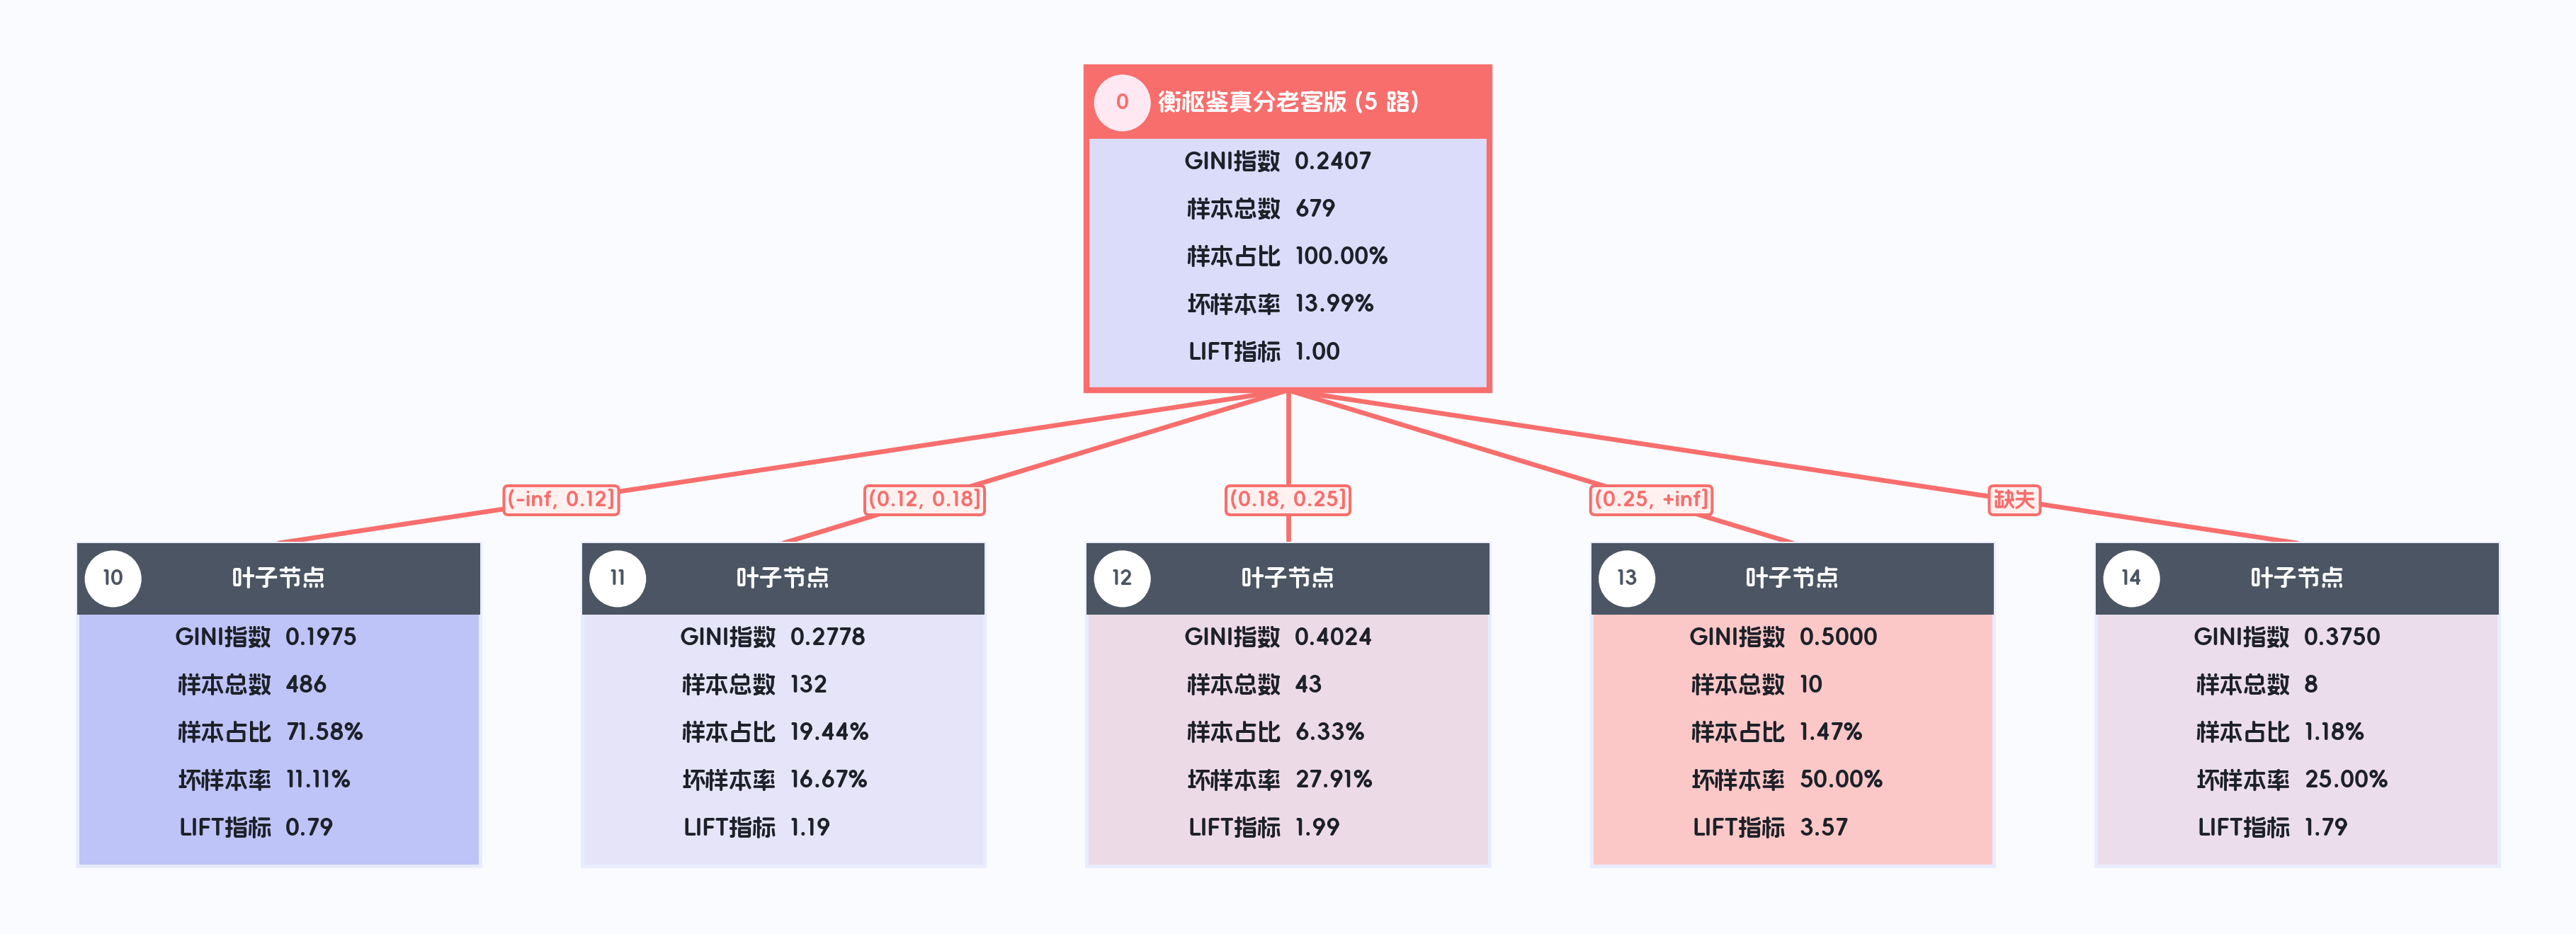

In [10]:
missing_training = train.copy()
missing_training.loc[missing_training.index[:8], features[0]] = np.nan
missing_tree = MultiwayTreeExtractor(
    target='FPD', features=features, max_depth=2, max_branches=5,
    missing_separate=True, n_jobs=1,
).fit(missing_training)
missing_tree.manual_split(feature=features[0], thresholds=[0.12, 0.18, 0.25], node=0, missing_separate=True)
root = missing_tree.nodes_[0]
assert len(root.children) == 5
missing_node = root.children[root.missing_branch]
assert missing_tree.nodes_[missing_node].counts.sum() == missing_training[features[0]].isna().sum()
fig = plot_tree(missing_tree, save=str(output_dir / '独立缺失五叉树.png'))
display(style_rule_table(missing_tree.get_rule_table(leaf_only=True)))

## 9. 将缺失值并入指定分支

数值 `thresholds` 中的 `np.nan` 位置表示合并目标普通分支：位于开头是 0，插在第一个切点之后是 1，依此类推。
显式 `missing_branch` 优先，因此末尾加 `np.nan` 同时传 `missing_branch=0` 也表示合并到第 0 支，不会新增分支。

`[0.12, np.nan, 0.18, 0.25]` 对应 `missing_branch=1`，两种写法比较时必须使用相同分支号。

,节点编号,是否叶子,指标含义,样本总数,样本占比,好样本数,好样本占比,坏样本数,坏样本占比,坏样本率,LIFT值,坏账改善,风险拒绝比,准确率,精确率,召回率,F1分数
0,15,是,"衡枢鉴真分老客版: (-inf, 0.12]",486,71.58%,432,73.97%,54,56.84%,11.11%,0.79,-51.84%,-72.42%,30.34%,11.11%,56.84%,18.59%
1,16,是,"衡枢鉴真分老客版: (0.12, 0.18] 或缺失",140,20.62%,116,19.86%,24,25.26%,17.14%,1.23,5.85%,28.38%,72.46%,17.14%,25.26%,20.43%
2,17,是,"衡枢鉴真分老客版: (0.18, 0.25]",43,6.33%,31,5.31%,12,12.63%,27.91%,1.99,6.72%,106.19%,83.21%,27.91%,12.63%,17.39%
3,18,是,"衡枢鉴真分老客版: (0.25, +inf]",10,1.47%,5,0.86%,5,5.26%,50.00%,3.57,3.85%,261.22%,86.01%,50.00%,5.26%,9.52%


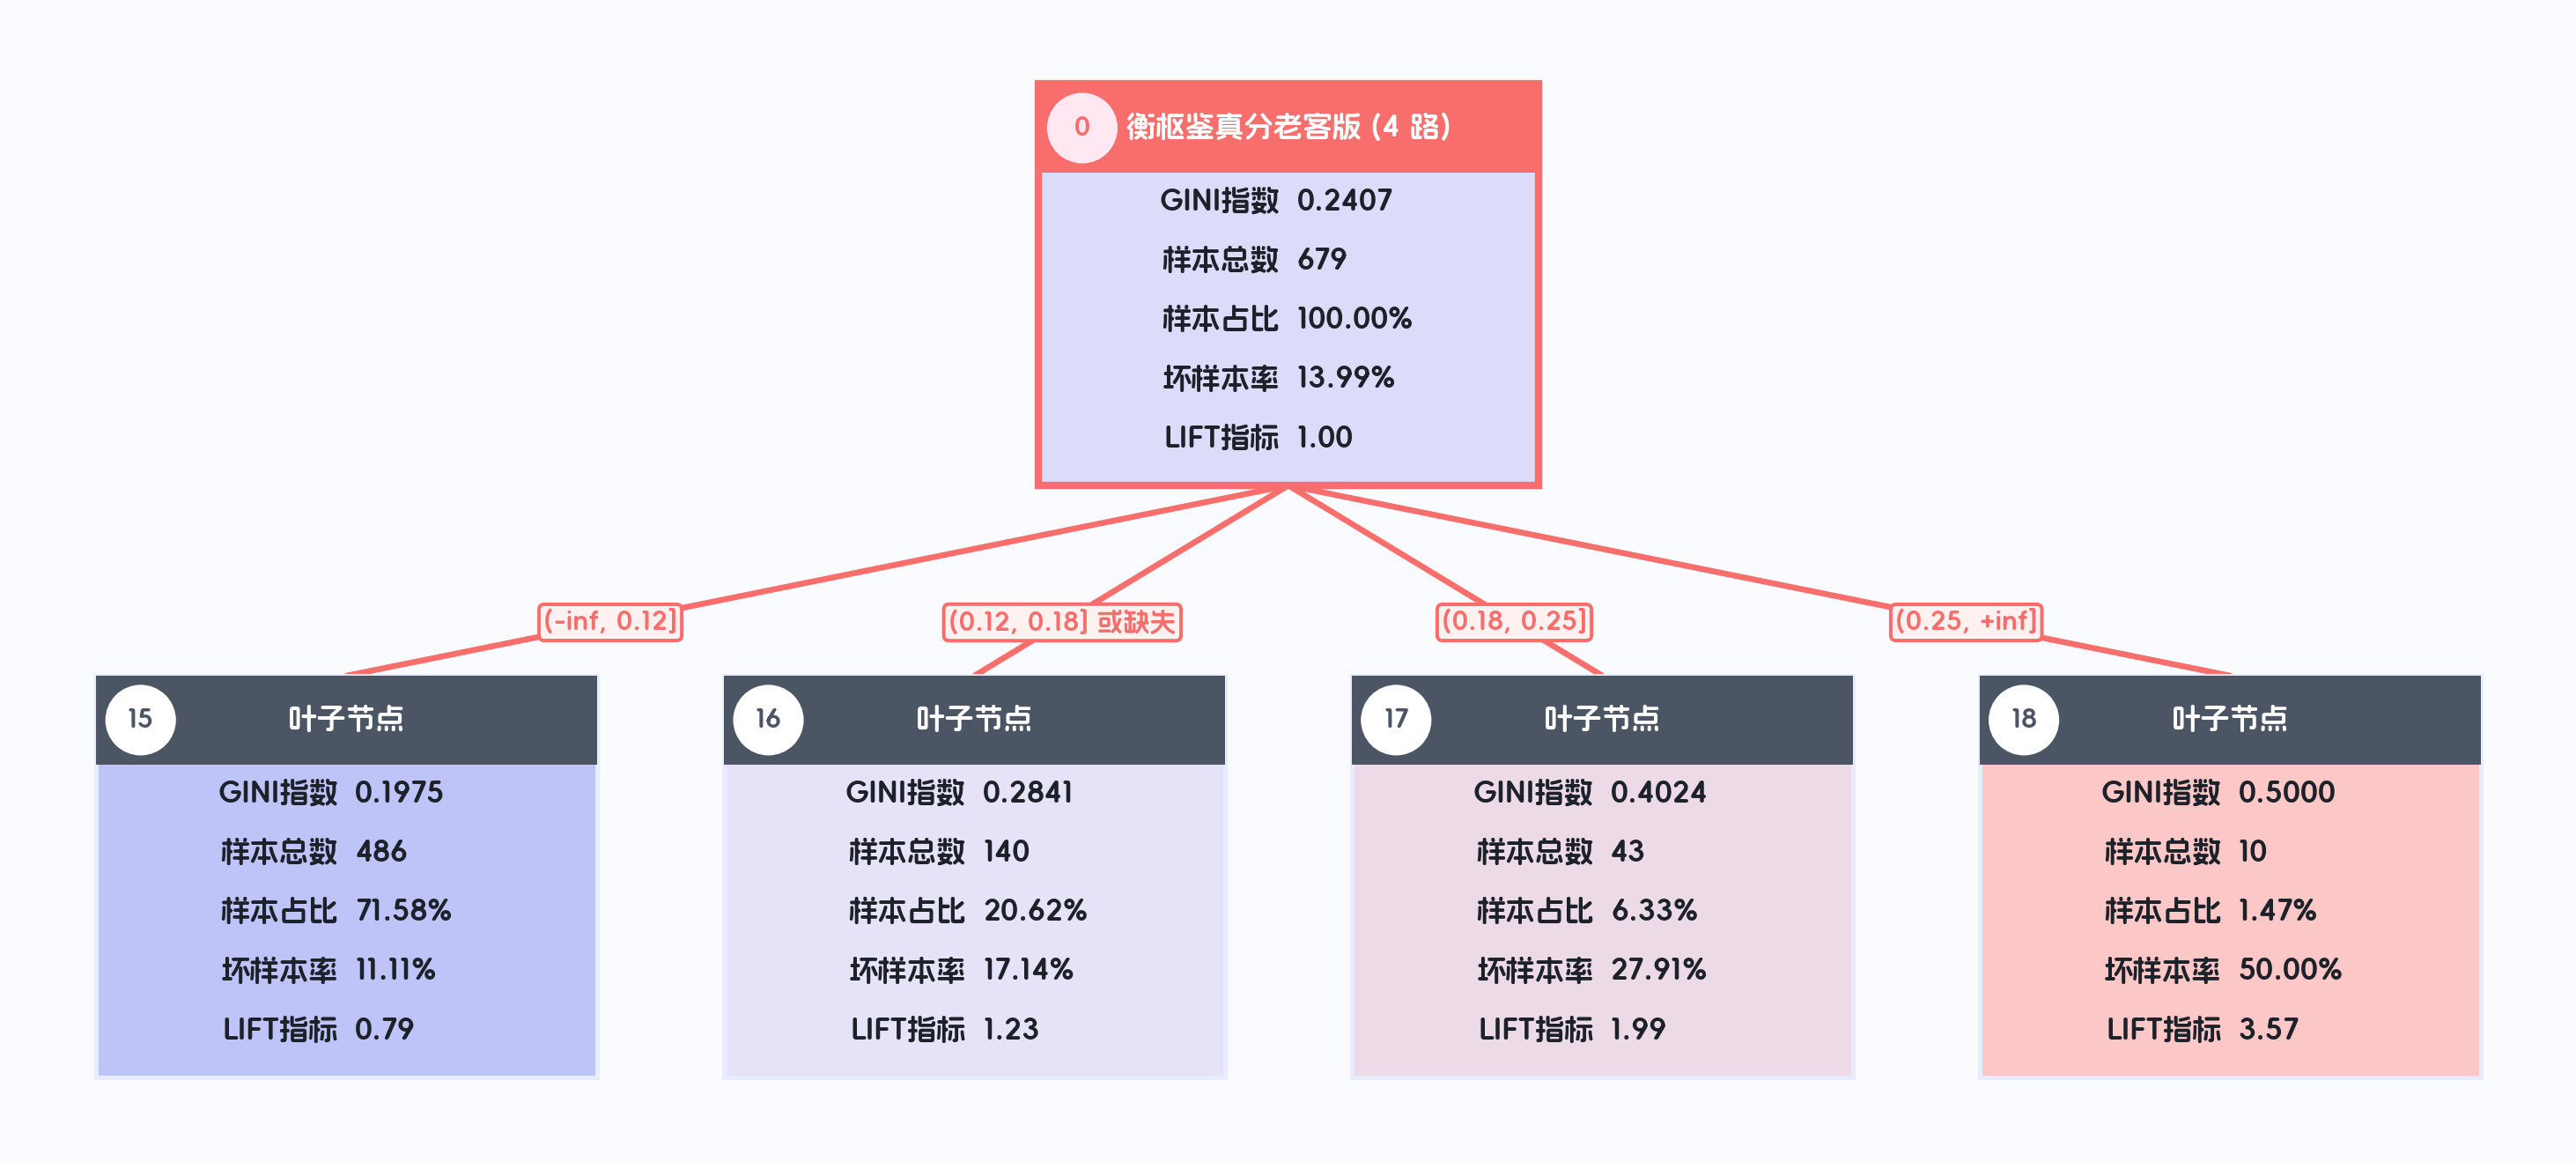

In [11]:
# 只需调整 merge_branch，缺失标记、显式参数和原始行验证会同步变化。
cuts = [0.12, 0.18, 0.25]
merge_branch = 1  # 0 为最左分支；1 对应 (0.12, 0.18]
marked_cuts = cuts.copy()
marked_cuts.insert(merge_branch, np.nan)
merged_tree = copy.deepcopy(missing_tree)
merged_tree.manual_split(feature=features[0], thresholds=marked_cuts, node=0)
assert len(merged_tree.nodes_[0].children) == 4
assert not merged_tree.nodes_[0].missing_separate
assert merged_tree.nodes_[0].missing_branch == merge_branch
explicit_tree = copy.deepcopy(missing_tree)
explicit_tree.manual_split(feature=features[0], thresholds=cuts + [np.nan], node=0, missing_branch=merge_branch)
np.testing.assert_allclose(merged_tree.predict_proba(missing_training), explicit_tree.predict_proba(missing_training))
values = missing_training[features[0]]
ordinary_mask = values.notna()
if merge_branch > 0:
    ordinary_mask &= values > cuts[merge_branch - 1]
if merge_branch < len(cuts):
    ordinary_mask &= values <= cuts[merge_branch]
mask = values.isna() | ordinary_mask
merged_node = merged_tree.nodes_[0].children[merge_branch]
assert merged_tree.nodes_[merged_node].counts.sum() == mask.sum()
np.testing.assert_array_equal(merged_tree.apply(missing_training) == merged_node, mask.to_numpy())
fig = plot_tree(merged_tree, save=str(output_dir / '缺失合并四叉树.png'))
display(style_rule_table(merged_tree.get_rule_table(leaf_only=True)))

## 10. 类别分组中的缺失标记

`[np.nan]` 是独立缺失组，`[类别, np.nan]` 将缺失与类别合并。
独立模式下未知类别走样本最多的普通分支，纯缺失分支只接收缺失值。

,节点编号,父节点,深度,是否叶子,分裂特征,切分点,类别分组,子节点,缺失分支,缺失独立分支,样本总数,规则表达式,类别_0样本数,类别_1样本数
0,0,NaN,0,否,商品类别,[],"[[珠宝首饰], [礼包], [手机通讯], [电脑数码, 智能设备, 家用电器]]","[6, 7, 8, 9]",0,否,679,True,584,95
1,6,0.0000,1,是,NaN,[],[],[],0,否,421,"((((商品类别 in ['珠宝首饰']) & (商品类别.notna())) | ((商品类别 not in ['珠宝首饰', '礼包', '手机通讯', '电脑数码', '智能设备', '家用电器']) & (商品类别.notna()))) | (商品类别.isna()))",354,67
2,7,0.0000,1,是,NaN,[],[],[],0,否,141,((商品类别 in ['礼包']) & (商品类别.notna())),125,16
3,8,0.0000,1,是,NaN,[],[],[],0,否,98,((商品类别 in ['手机通讯']) & (商品类别.notna())),88,10
4,9,0.0000,1,是,NaN,[],[],[],0,否,19,"((商品类别 in ['电脑数码', '智能设备', '家用电器']) & (商品类别.notna()))",17,2


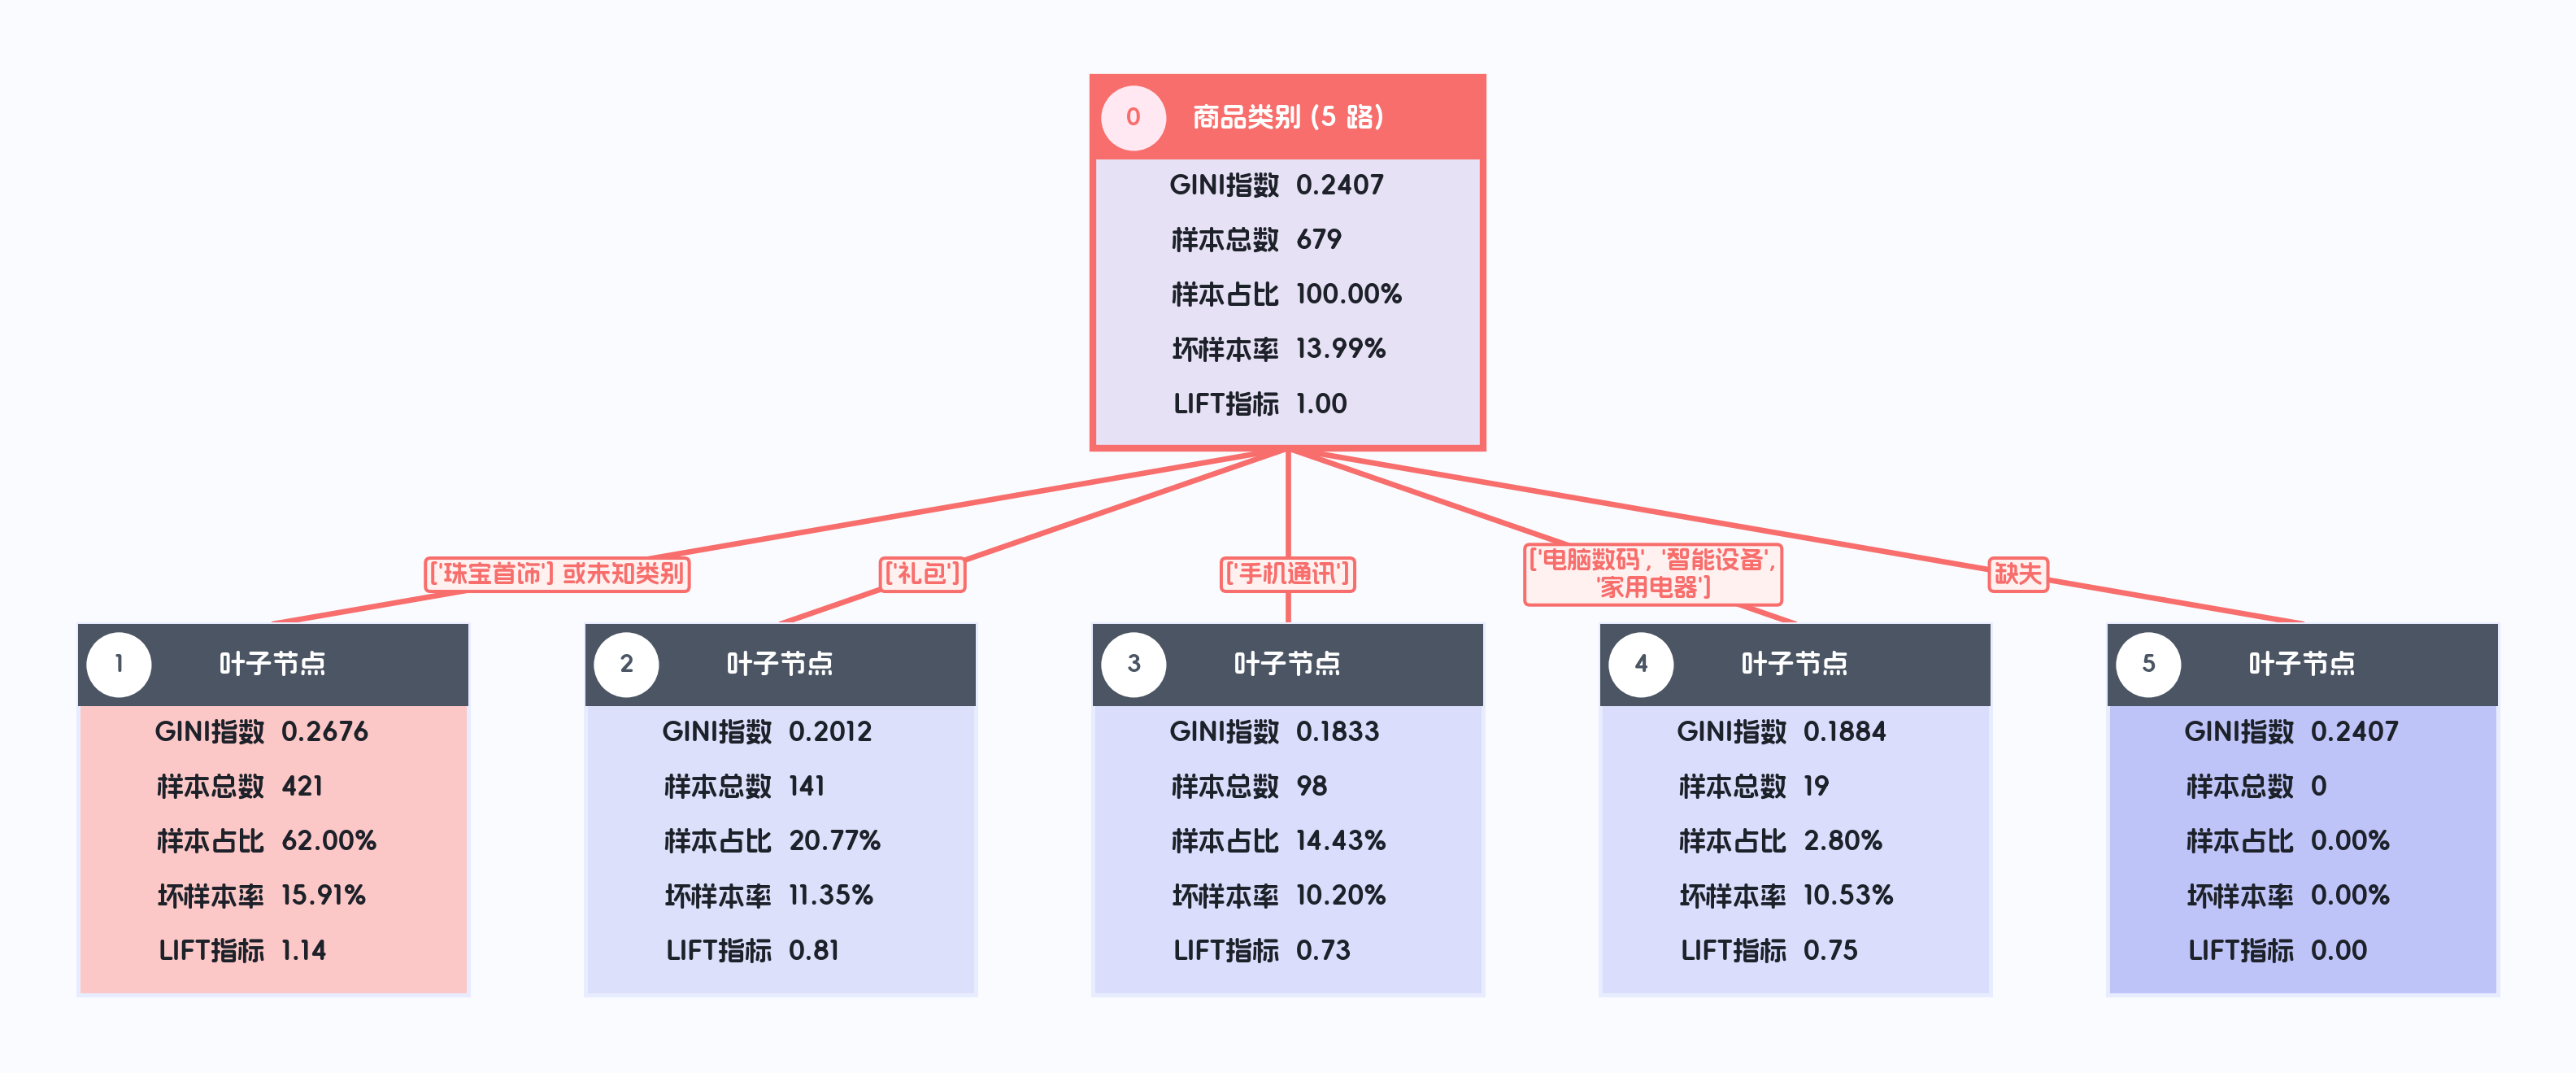

In [12]:
category_values = train['商品类别'].dropna().unique().tolist()
ordinary_groups = [[value] for value in category_values[:3]]
if len(category_values) > 3:
    ordinary_groups.append(category_values[3:])
category_missing_tree = MultiwayTreeExtractor(target='FPD', features=['商品类别'], max_depth=1, max_branches=5, n_jobs=1).fit(train)
category_missing_tree.manual_split(feature='商品类别', category_groups=ordinary_groups + [[np.nan]])
assert category_missing_tree.nodes_[0].missing_separate
fig = plot_tree(category_missing_tree, save=str(output_dir / '类别独立缺失分支.png'))
merged_groups = copy.deepcopy(ordinary_groups)
merged_groups[0].append(np.nan)
category_missing_tree.manual_split(feature='商品类别', category_groups=merged_groups)
assert not category_missing_tree.nodes_[0].missing_separate
display(category_missing_tree.get_node_table())

## 11. 训练时无缺失，生产中新出现缺失

未指定缺失策略时，按当前节点的训练样本判断：有缺失则学习合并方向，无缺失则默认走最左（0 号）分支。
显式 `missing_branch`、`thresholds` 中的缺失标记和 `missing_separate=True` 始终按声明生效。
下面在真实数据副本中模拟生产缺失，并核对叶节点、预测概率与导出规则。
已保存模型保留原有路由；更新库后需重启内核、重新训练或重新分裂节点。

,节点编号,是否叶子,指标含义,样本总数,样本占比,好样本数,好样本占比,坏样本数,坏样本占比,坏样本率,LIFT值,坏账改善,风险拒绝比,准确率,精确率,召回率,F1分数
0,3,是,"衡枢鉴真分老客版: (-inf, 0.12] 或缺失",5,100.00%,3,100.00%,2,100.00%,40.00%,1.00,100.00%,-,40.00%,40.00%,100.00%,57.14%
1,4,是,"衡枢鉴真分老客版: (0.12, 0.18]",0,0.00%,0,0.00%,0,0.00%,0.00%,0.00,0.00%,0.00%,60.00%,0.00%,0.00%,0.00%
2,5,是,"衡枢鉴真分老客版: (0.18, 0.25]",0,0.00%,0,0.00%,0,0.00%,0.00%,0.00,0.00%,0.00%,60.00%,0.00%,0.00%,0.00%
3,6,是,"衡枢鉴真分老客版: (0.25, +inf]",0,0.00%,0,0.00%,0,0.00%,0.00%,0.00,0.00%,0.00%,60.00%,0.00%,0.00%,0.00%


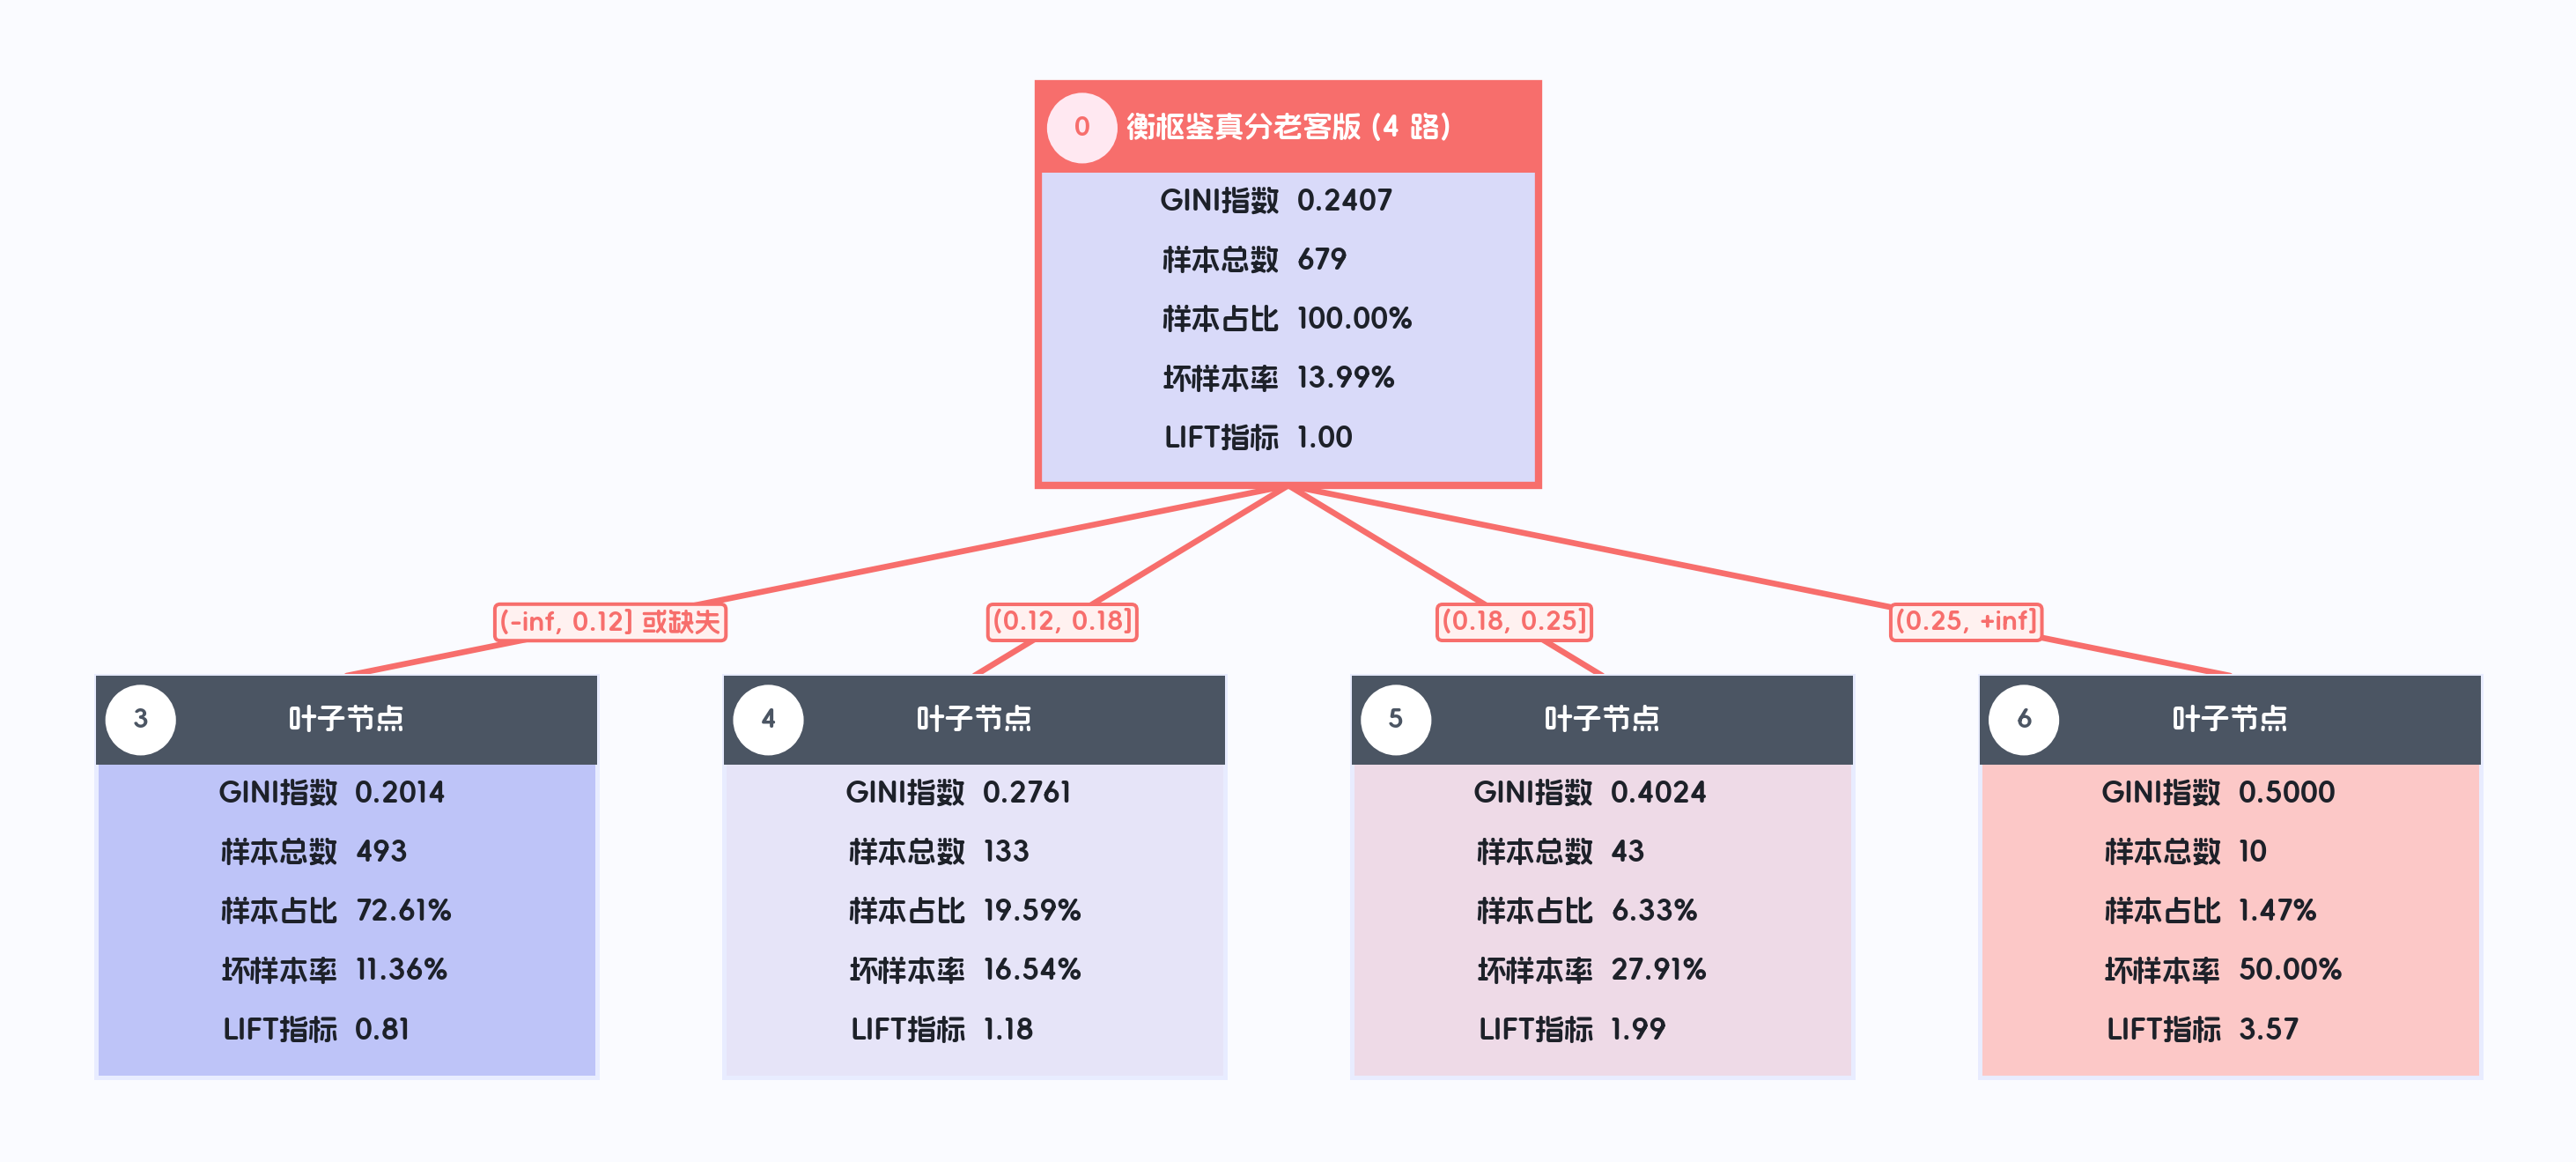

In [13]:
complete_training = train.dropna(subset=[features[0]]).copy()
future_tree = MultiwayTreeExtractor(
    target='FPD', features=features, max_depth=1, max_branches=4, n_jobs=1,
).fit(complete_training)
future_tree.manual_split(feature=features[0], thresholds=[0.12, 0.18, 0.25])
future_root = future_tree.nodes_[0]
assert future_root.missing_branch == 0
production = complete_training.iloc[:5].copy()
production[features[0]] = np.nan
assert np.all(future_tree.apply(production) == future_root.children[0])
left_training = complete_training.loc[complete_training[features[0]] <= 0.12]
np.testing.assert_allclose(future_tree.predict_proba(production)[:, 1], left_training['FPD'].mean())
for node_id, rule in zip(future_tree.get_leaf_node_ids(), future_tree.get_rules()):
    np.testing.assert_array_equal(rule.predict(production).to_numpy(), future_tree.apply(production) == node_id)
explicit_future = copy.deepcopy(future_tree)
explicit_future.manual_split(feature=features[0], thresholds=[0.12, 0.18, 0.25], missing_branch=2)
assert np.all(explicit_future.apply(production) == explicit_future.nodes_[0].children[2])
fig = plot_tree(future_tree, save=str(output_dir / '训练无缺失默认走最左分支.png'))
display(style_rule_table(future_tree.get_rule_table(production, leaf_only=True)))